# data_driven_plan — Cluster-Predict-Schedule pipeline

Data-driven outpatient appointment scheduling: no-show and service-time group prediction, feeding a stochastic overbooking ILP (at most k = 2 patients per slot).

A single CRISP-DM pipeline. All utility functions live in `data_driven_plan.py` — this notebook holds only the orchestration, the narrative and the outputs.

**Previously validated results, reproduced identically:** K=2 (service_time clustering, bootstrapped silhouette), cutoff ~38.5 min (decision tree), XGBoost as best no-show classifier.

In [1]:
# ── Configuration and reproducibility ─────────────────────────────────────────
import sys, platform, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

sys.path.insert(0, ".")
from data_driven_plan import *

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)
ensure_output_dirs()

print(f"Python   : {sys.version.split()[0]}")
print(f"NumPy    : {np.__version__}")
print(f"Pandas   : {pd.__version__}")
print(f"Platform : {platform.processor()}")
print(f"ILP solver : {SOLVER_NAME}")
print(f"Native XGBoost: {XGB_AVAILABLE} | SMOTE available: {SMOTE_AVAILABLE}")


Native XGBoost: True | SMOTE available: True
Python   : 3.11.13
NumPy    : 2.4.6
Pandas   : 3.0.3
Platform : x86_64
ILP solver : appsi_highs
Native XGBoost: True | SMOTE available: True


## 1. Business Understanding

**Decision objective:** reduce slot idle time and patient waiting time in an outpatient clinic by allowing controlled overbooking (at most two patients per slot), which compensates for no-shows without degrading the patient experience excessively.

For each patient to be scheduled, the stochastic ILP (section 7) needs two predicted quantities:
- **q_i**: calibrated show-up probability (1 − P(no-show));
- **group**: service-time class (A = long, B = short), which sets the   deterministic duration `s_i` used in the model.

Sections 2 to 6 build and validate these two predictive models; section 7 uses them to solve real ILP instances.

## 2. Data Understanding

### 2.1 Initial collection

The raw data (`$SMART_PLAN_DATA/raw_data_parquet/`, derived from `data/consult_waits_2024_03_25.csv` by `scripts/csv_to_parquet.py`) covers outpatient consultations with their scheduled and realised times (`dts`/`dtc`), the attendance status (`disp`) and administrative metadata (facility, clinic stop code, region).

In [2]:
# ── 2.1 Load the raw data ─────────────────────────────────────────────────────
# Paths come from the module and follow SMART_PLAN_DATA (default: ./data), so
# this notebook runs unchanged wherever the dataset lives.
print(f"Data root: {DATA_DIR}")
data = pd.read_parquet(RAW_PARQUET_DIR, engine="pyarrow")
print(f"Raw shape: {data.shape}")
data.info(memory_usage="deep")
data.head()


Data root: /workspace/data


Raw shape: (51874107, 12)
<class 'pandas.DataFrame'>
RangeIndex: 51874107 entries, 0 to 51874106
Data columns (total 12 columns):
 #   Column              Dtype   
---  ------              -----   
 0   patientsid          uint32  
 1   activitydatetime    str     
 2   sta3n               category
 3   stopcode            category
 4   dta                 float32 
 5   dts                 uint16  
 6   dtc                 uint16  
 7   non_va              category
 8   zip                 category
 9   state               category
 10  disp                category
 11  AdministrativeFlag  category
dtypes: category(7), float32(1), str(1), uint16(2), uint32(1)
memory usage: 2.4 GB


,patientsid,activitydatetime,sta3n,stopcode,dta,dts,dtc,non_va,zip,state,disp,AdministrativeFlag
0,9204541,2023-06-15 14:43:56,573,354,5.0,3,0,1,315,GEORGIA,COMPLETE/UPDATE,Y
1,9204541,2017-02-01 10:20:10,573,403,0.0,30,64,0,315,GEORGIA,COMPLETE/UPDATE,NaN
2,9204541,2021-11-03 09:32:28,573,407,2.0,54,48,1,315,GEORGIA,COMPLETE/UPDATE,Y
3,9204541,2015-03-26 14:30:45,573,408,1.0,134,149,0,315,GEORGIA,COMPLETE/UPDATE,NaN
4,9204541,2019-02-08 12:41:00,573,409,0.0,28,44,0,315,GEORGIA,COMPLETE/UPDATE,NaN


### 2.2 Target description and class imbalance

`disp` is decomposed immediately into binary indicators (`NoShow`/`discontinued`) so that class imbalance can be quantified from the exploration stage onwards.

**The `completed` indicator is deliberately not created:** together with `discontinued` it reconstructs the target (NoShow ≈ 1 − completed − discontinued) and biases no-show prediction as soon as it reaches the features. Never producing it removes the risk at the source rather than relying on a downstream exclusion. Nothing is lost: `NoShow` already encodes CANCELLED and `discontinued` the third state, so the COMPLETE/UPDATE category follows from the two.

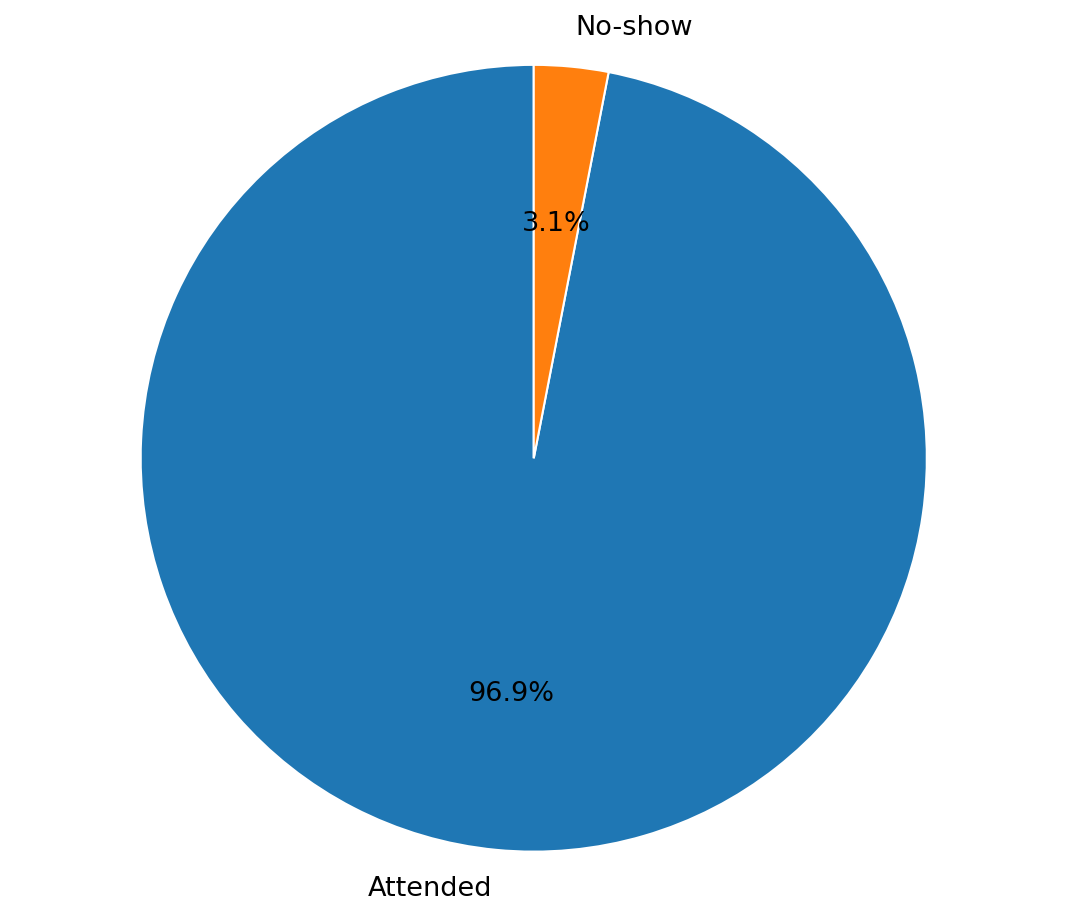

NoShow
0    0.969479
1    0.030521
Name: proportion, dtype: float64


In [3]:
# ── 2.2 Target decomposition + class imbalance ───────────────────────────────
data = decompose_disp_column(data, disp_column="disp")
plot_target_balance(data, "NoShow", labels={0: "Attended", 1: "No-show"}, prefix="eda")
print(data["NoShow"].value_counts(normalize=True).rename("proportion"))


The observed no-show rate (~3%) is far more imbalanced than the initial 85/15 assumption — which drives the choice of imbalance strategy (SMOTE + class weighting + optimal threshold, section 4a) and makes calibration (section 5) more important than discrimination alone.

### 2.3 Exploring the numeric and temporal variables

`dta` (waiting time before the appointment) and `dts`/`dtc` (service start/end) are explored before cleaning — their raw values contain inconsistencies (dts > dtc) handled in Data Preparation.

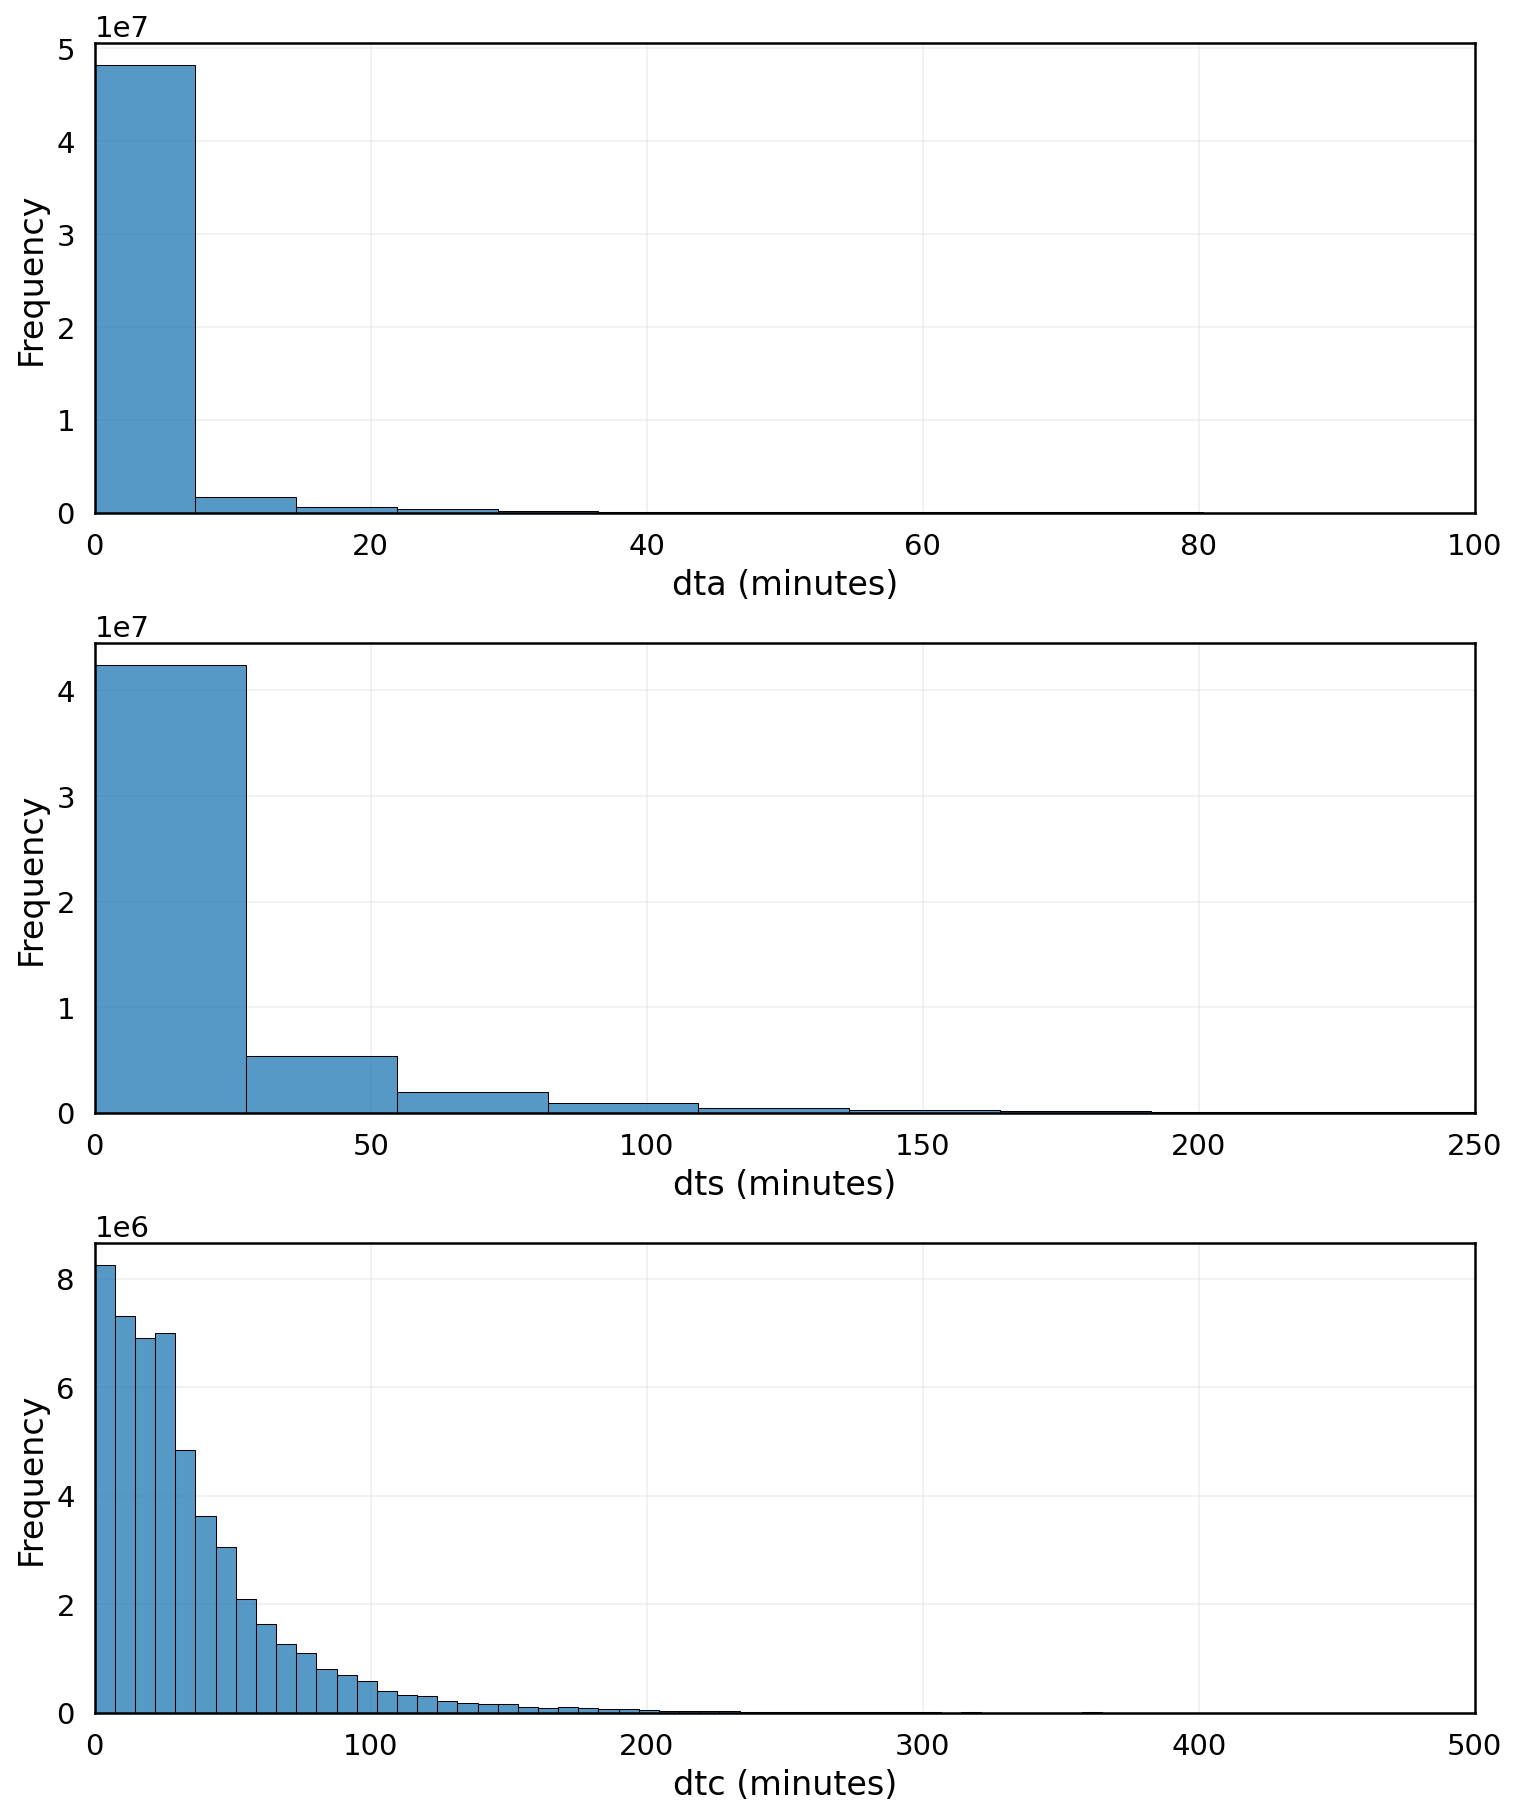

In [4]:
# ── 2.3 Raw numeric distributions ─────────────────────────────────────────────
plot_numeric_histograms(data, ["dta", "dts", "dtc"], bins=[50, 50, 50],
                        xlims=[(0, 100), (0, 250), (0, 500)], prefix="eda")


In [5]:
# ── 2.3 (cont.) Missing values ────────────────────────────────────────────────
missing_pct = display_missing_values(data, sentinel_col="state", sentinel_value="*Missing*")
print(missing_pct[missing_pct > 0].sort_values(ascending=False))


Percentage of missing values per column:
AdministrativeFlag    61.092975
zip                    0.001639
state                  0.001211
dtype: float64


`AdministrativeFlag` exceeds 55% missing values: reliable imputation is illusory at that rate, so the column is dropped rather than imputed (section 3). `zip`/`state` are missing for a marginal share of rows — listwise deletion is preferred to imputation, with no material impact on a dataset of this size.

Outlier count (IQR) per numeric column: {'patientsid': 0, 'dta': 5461594, 'dts': 4799072, 'dtc': 3220482, 'NoShow': 1583252, 'discontinued': 834729}


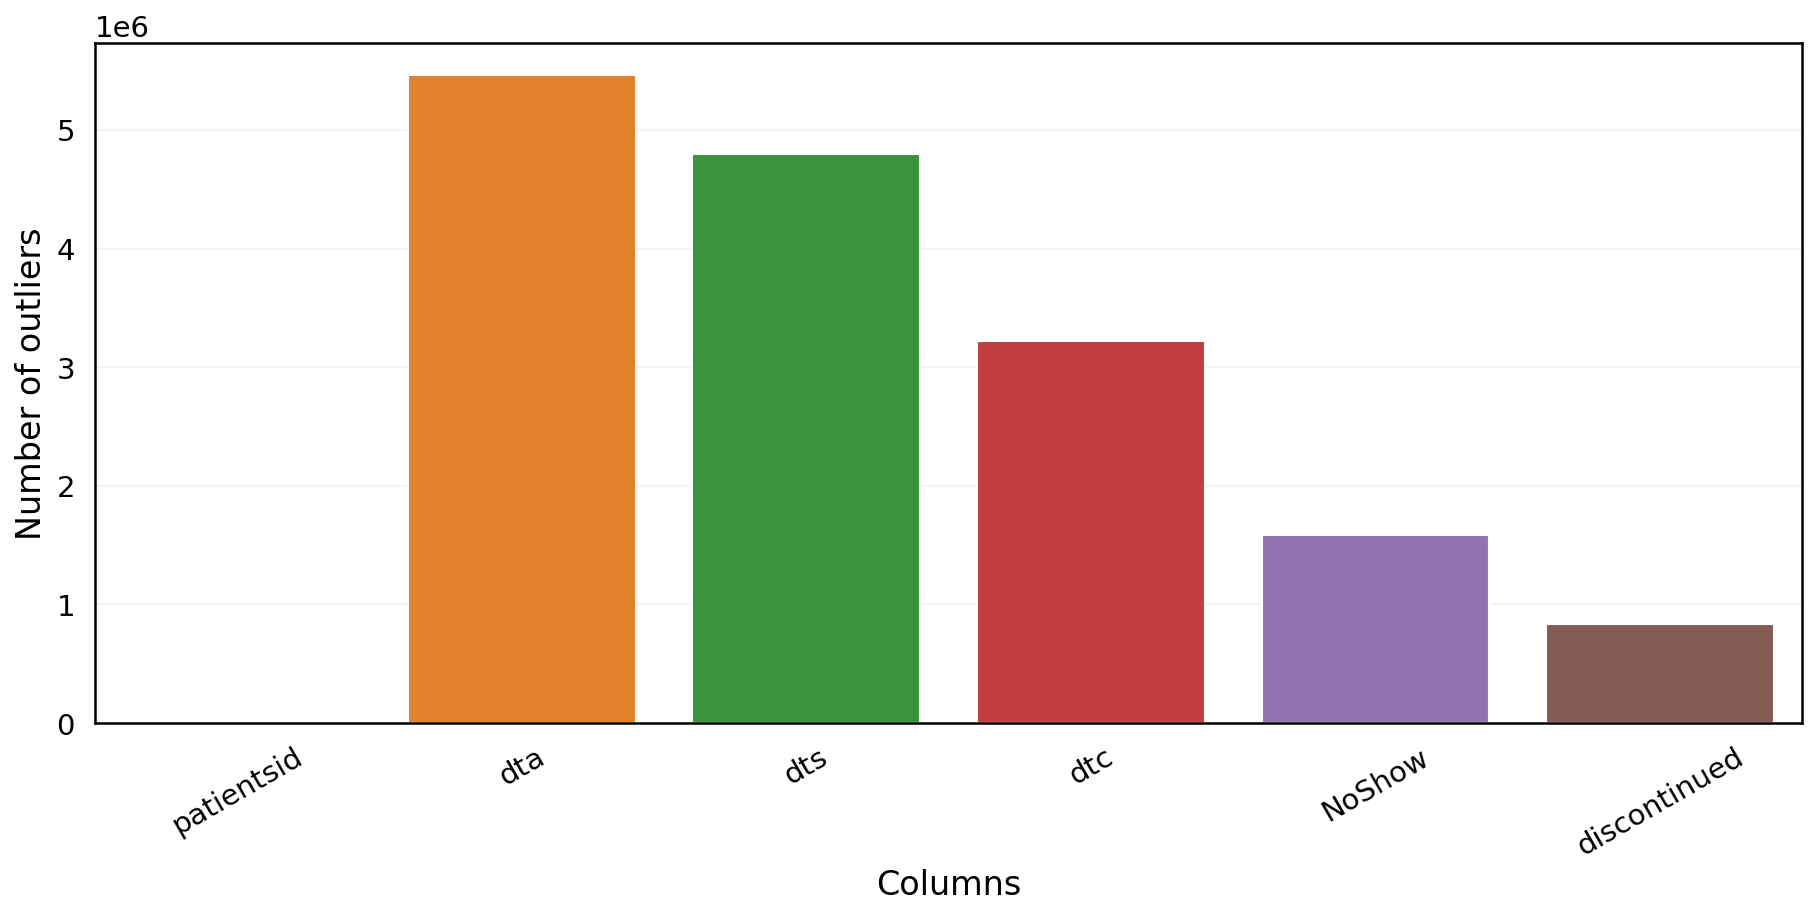

In [6]:
# ── 2.3 (cont.) Outlier diagnostic (IQR) — visualisation only ────────────────
visualize_outliers(data, prefix="eda")


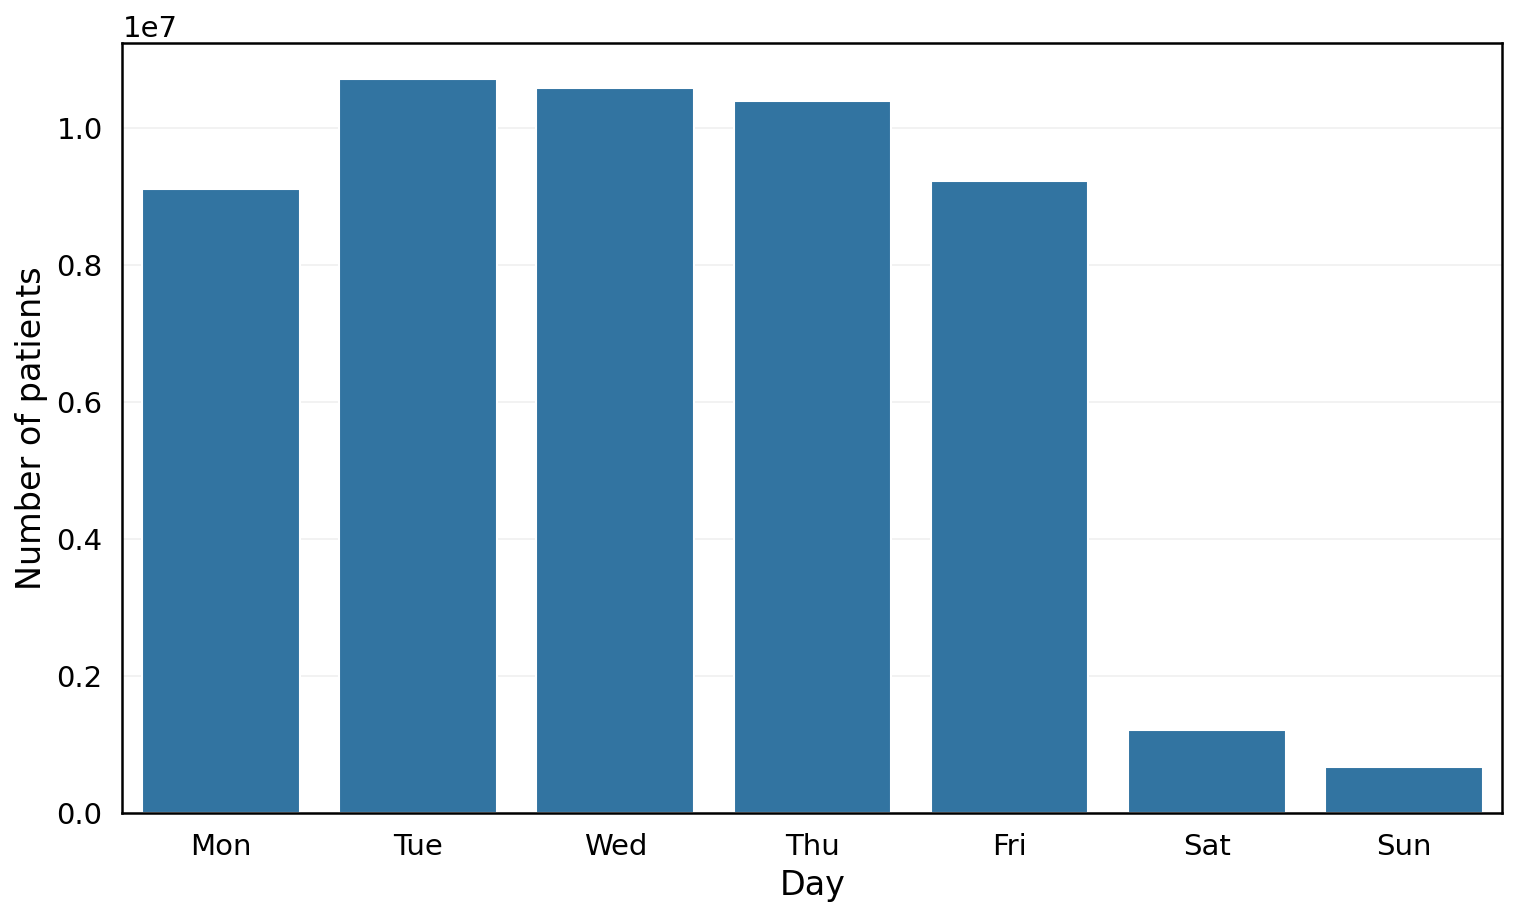

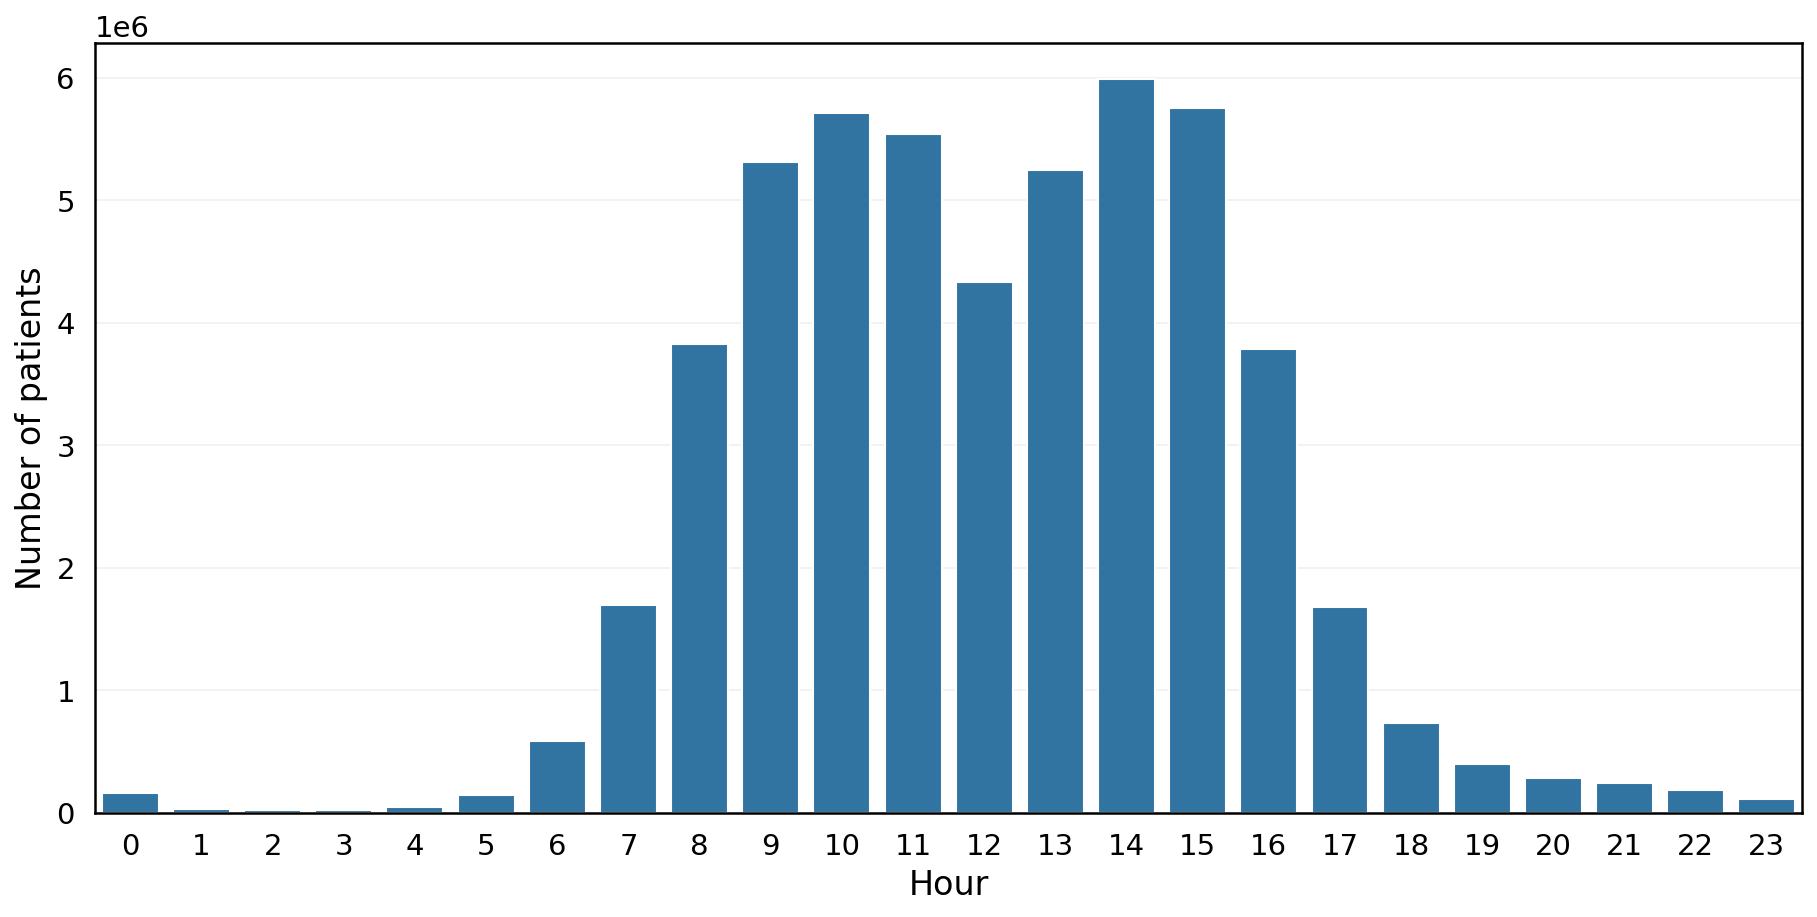

In [7]:
# ── 2.3 (cont.) Activity patterns (weekday / hour) ───────────────────────────
_ = analyze_temporal_patterns(data, "activitydatetime", prefix="eda")


## 3. Data Preparation

### 3.1 Cleaning

**Temporal filtering:** data prior to 2016-08-30 is excluded — it predates a major operational reorganisation (launch of the Veteran Choice Program) that durably changed waiting times and therefore no-show rates; including it would bias learning towards an obsolete operating regime.

In [8]:
# ── 3.1 Temporal filtering + calendar features ────────────────────────────────
data = filter_dates_after(data, "activitydatetime", "2016-08-30 00:00:00")
data = add_temporal_features(data, "activitydatetime")
print(f"Shape after temporal filtering: {data.shape}")


Shape after temporal filtering: (42733202, 17)


In [9]:
# ── 3.1 Missing values: column and row removal ───────────────────────────────
data = drop_high_missing_columns(data, ["AdministrativeFlag"])
data = drop_missing_rows(data, ["zip", "state"], missing_sentinels={"state": "*Missing*"})
print(f"Shape after missing-value handling: {data.shape}")


Shape after missing-value handling: (42732509, 16)


**dts/dtc consistency:** a record whose service end time precedes its start time (`dtc < dts`) reflects a data-entry error — `service_time` would not be interpretable there. Those rows are removed, including the rare `NoShow=1` cases with `dts>dtc` (the patient's absence makes `dtc` meaningless).

In [10]:
# ── 3.1 dts/dtc consistency + duplicates + service_time ──────────────────────
data = filter_dts_dtc_consistency(data, "dts", "dtc", "NoShow")
data = data.drop_duplicates()
data = compute_service_time(data, "dts", "dtc")
print(f"Shape after dts/dtc consistency + deduplication: {data.shape}")


Shape after dts/dtc consistency + deduplication: (40140652, 16)


### 3.2 Transformation

**Stop-code filtering:** only clinic codes that have recorded at least one no-show are kept — a stop code with no no-show history carries no discriminating signal for this task and dilutes the training sample.

In [11]:
# ── 3.2 Filter out stop codes with no no-show history ────────────────────────
data, _data_without_ns, _codes_dropped = separate_stopcodes_by_no_show(data)
print(f"Stop codes excluded (never any no-show): {len(_codes_dropped)}")
print(f"Shape after stop-code filtering: {data.shape}")


Stop codes excluded (never any no-show): 54
Shape after stop-code filtering: (40133413, 16)


**Patient history features:** days since the previous visit (per patient/stop code) and running averages of prior no-shows and prior service times (per patient), lagged by one rank to exclude any information leaking from the current visit.

In [12]:
# ── 3.2 Patient history features ──────────────────────────────────────────────
data = add_patient_history_features(data, "patientsid", "stopcode", "activitydatetime",
                                    "NoShow", "service_time")
print(data[["days_between_visits", "prior_noShow_rate", "prior_service_time_avg"]].describe())


       days_between_visits  prior_noShow_rate  prior_service_time_avg
count         4.013341e+07       4.013341e+07            4.013341e+07
mean          9.737003e+01       1.695067e-02            1.609191e+01
std           3.533009e+02       8.129830e-02            1.460461e+01
min           0.000000e+00       0.000000e+00            0.000000e+00
25%           0.000000e+00       0.000000e+00            4.666667e+00
50%           0.000000e+00       0.000000e+00            1.483333e+01
75%           0.000000e+00       0.000000e+00            2.305882e+01
max           2.556000e+03       1.000000e+00            3.650000e+02


In [13]:
# ── 3.2 Final feature selection + checkpoint ─────────────────────────────────
data = data.drop(columns=["activitydatetime", "patientsid"])
print(f"Final preprocessed shape: {data.shape}")
print(f"Columns: {data.columns.tolist()}")
save_preprocessed_data(data, PREPROCESSED_PATH)
print(f"Saved -> {PREPROCESSED_PATH}")


Final preprocessed shape: (40133413, 17)
Columns: ['sta3n', 'stopcode', 'dta', 'dts', 'non_va', 'zip', 'state', 'NoShow', 'discontinued', 'day_of_week', 'day_of_month', 'month', 'hour', 'service_time', 'days_between_visits', 'prior_noShow_rate', 'prior_service_time_avg']


Saved -> /workspace/data/preprocessed/preprocessed_data.parquet


### 3.2bis Fast resume point (optional)

Section 2 (Data Understanding) and sections 3.1-3.2 (cleaning + feature engineering) are expensive on the 40M+ raw rows. If the preprocessed Parquet file already exists from a previous run, the cell below skips them entirely when resuming: run only the configuration cell at the very top, uncomment and run this one, then continue normally from section 3.3. On a full run from the raw data, leave it commented out (the `data` already in memory is identical).

**Parquet rather than CSV:** it preserves the optimised dtypes (category, uint32, float32...) — a CSV round-trip would restore them as object/int64/float64, multiplying the memory footprint of a dataset of this size.

In [14]:
# ── 3.2bis Fast resume: reload the preprocessed data instead of sections 2-3.2 ──
# data = load_preprocessed_data(PREPROCESSED_PATH)
# print(f"Preprocessed data reloaded: {data.shape}")


### 3.3 Single partition

One split, stratified jointly on `NoShow` (strong imbalance) and on `service_time` quantiles, guarantees that BOTH modelling pipelines (no-show and service time) inherit a representative train/test split, with no leakage between them or with the ILP holdout — reserved exclusively for patients never seen during training (section 7).

**The full set of rows is used** (no subsampling at this stage): the split yields exactly 70% train / 20% test / 10% inference holdout of the total. Subsampling to 800k rows, consistent with the already validated clustering (K=2, bootstrapped silhouette), happens later, when the models are trained (section 4), to keep AdaBoost/ANN tractable.

In [15]:
# ── 3.3 Single split (train / test / ILP holdout) ────────────────────────────
df_sample, train_df, test_df, df_inference = make_master_split(
    data, train_size=0.70, test_size=0.20, inference_size=0.10,
    noshow_col="NoShow", service_time_col="service_time",
    n_quantile_bins=10, random_state=RANDOM_STATE,
)


Full dataset used as working sample: 40,133,413 rows


  Inference holdout : 4,013,341  (10.0%)  -- never seen by the models
  Train             : 28,093,389  (70.0%)
  Test              : 8,026,683  (20.0%)
  NoShow rate (Inference) : 0.0317  |  median service_time: 14.0 min


  NoShow rate (Train    ) : 0.0317  |  median service_time: 14.0 min
  NoShow rate (Test     ) : 0.0317  |  median service_time: 14.0 min


  Inference holdout saved -> /workspace/data/inference/inference_set_raw.csv  (seed=0, stratified NoShow x service_time)


**Leakage warning:** `discontinued` (section 2.2) is derived from the same source column `disp` as `NoShow`, and is not known before the appointment in any case — it is therefore excluded from the features, like the targets themselves. `completed`, which made the target reconstructible (NoShow ≈ 1 − completed − discontinued), is no longer produced at all since section 2.2; it is nevertheless still listed below as a safeguard, in case the fast resume path (section 3.2bis) reloads a Parquet file preprocessed by an earlier run.

**Real-world availability warning:** `dts` (actual service start) and `dta` (waiting time before the appointment) are known only once the visit is under way or finished — at the moment the prediction must actually be used (before the appointment, to decide on overbooking), they do not yet exist. `dtc` is already dropped after `service_time` is computed (section 3.1); `dts`/`dta` are therefore excluded from the features too, even though they remain in `data` for now.

In [16]:
# ── 3.3 Encoding + standardisation (fitted on train only) ────────────────────
X_train, X_test, X_inference, feature_cols, scaler, cat_encodings = prepare_features(
    train_df, test_df, inference_df=df_inference,
    categorical_cols=["stopcode", "sta3n", "non_va", "state", "zip"],
    onehot_max_cardinality=150,   # one-hot below this, integer code above
    excluded_cols={"service_time", "NoShow", "group_label", "cluster",
                   "discontinued", "dts", "dta",
                   "completed"},  # safeguard: no longer produced, except in an older Parquet
    random_state=RANDOM_STATE,
)


Features: 12 | Numeric: 7 | Categorical one-hot: 3 (197 columns) | Categorical ordinal: 2
   one-hot  sta3n       130 levels
   one-hot  non_va        2 levels
   one-hot  state        65 levels
   ordinal  stopcode    305 levels (too many to expand)
   ordinal  zip         919 levels (too many to expand)


X_train: (28093389, 206) | X_test: (8026683, 206) | X_inference: (4013341, 206)


## 4. Modeling

Two parallel sub-pipelines, on the SAME split and the SAME features (section 3.3): no-show prediction (4a) and service-time group assignment (4b). Both reuse the single function `train_binary_classifiers` (RandomForest, XGBoost, AdaBoost, ANN — SMOTE + class weighting + optimal threshold).

`train_df` (70% of the full dataset, potentially tens of millions of rows) acts as a reservoir, but the final model fit runs on a bounded subsample `fit_sample` drawn from `train_df` — AdaBoost and the scikit-learn MLP (sequential, non-distributed implementations) would be impractical on the full training set. The tuning subsample (`search_sample`) is itself drawn from that fit subsample.

**No hyperparameter is hard-coded in the module:** section 4.0 below gathers every training lever into an editable `TrainingConfig`, and section 4c provides the tuning loop (variant → re-evaluation → comparison).

### 4.0 Training control panel

Each lever, what it changes, and when to touch it:

| Setting | Effect | Tuning hint |
|---|---|---|
| `models` | families trained | keep only one (e.g. `["XGBoost"]`) to iterate fast, then reopen |
| `search` | `grid` exhaustive / `random` (n_iter draws) / `none` (direct fit) | `random` affords far wider grids at equal budget |
| `n_iter` | budget of `search="random"` | 40-60 explores a wide space seriously |
| `cv` | cross-validation folds of the tuning | 5 for a more stable choice, 2 to go fast |
| `scoring` | score optimised by the search | `average_precision` suits ~3% positives better than `roc_auc`; `recall` when missing a no-show is costly |
| `search_sample` | tuning rows | raising it makes hyperparameter selection more reliable (roughly linear cost) |
| `fit_sample` / `fit_sample_by_model` | final fit rows, globally or per family | `None` = the whole `train_df`; the sequential families (AdaBoost, ANN) need a ceiling |
| `use_smote` / `smote_params` | synthetic oversampling of the tuning subset | `{"sampling_strategy": 0.3}` avoids the overcorrection of full SMOTE |
| `balance_classes` / `scale_pos_weight` | class weighting | three imbalance mechanisms stack up: switching one off can improve precision |
| `param_grids` / `base_params` | grids explored / fixed hyperparameters | `DEFAULT_PARAM_GRIDS` is the starting point, printed below |
| `threshold_metric` | decision-threshold criterion | `f1_positive` or `youden` favour no-show recall — **without retraining** |

Reported metrics are fixed: **AUC, accuracy, precision, recall, F1-score**, the last three macro-averaged over both classes.

**On rebalancing.** SMOTE is no longer applied to the tuning subset before the cross-validation: interpolated copies of a minority point ended up in the validation fold while its neighbours stayed in the training fold, so the CV score measured memorisation of synthetic data (0.99 ROC-AUC against 0.75 on the test set) and the search kept whichever model memorised best — a forest of unlimited depth. Rebalancing now happens strictly inside each fold: class weights for the tree families, SMOTE inside the ANN pipeline.

**On the ANN.** `MLPClassifier` accepts neither `class_weight` nor `sample_weight`, so it was the only family left untreated against a 3% positive rate and collapsed onto the majority class. It is now fitted inside an imbalanced-learn pipeline that applies SMOTE during training only, and searched over a wider space (three architectures, three regularisation levels, two learning rates).

The split (section 3.3), clustering (4b) and calibration (5.2) settings stay in their own cells.

In [17]:
# ── 4.0 Training settings — no-show ───────────────────────────────────────────
# Edit here, rerun 4a, compare with training_history_table() (4c).
TRAIN_CFG_NOSHOW = TrainingConfig(
    models=["RandomForest", "XGBoost", "AdaBoost", "ANN"],  # families to train
    search="random",                # "grid" | "random" | "none"
    n_iter=12,                      # draws when search="random"
    cv=3,                           # cross-validation folds of the tuning
    scoring="f1_macro",             # optimise the search on the reported metric,
                                    # not on ranking quality (roc_auc)
    search_sample=40_000,           # tuning rows     (None = all of X_fit)
    # Sized from the timings measured on this machine with the ~200-column
    # design matrix: RandomForest 204 s for 2M rows, XGBoost 50 s for 5M. The
    # sequential families are the constraint, and section 4 trains every family
    # TWICE (no-show, then A/B group).
    fit_sample=2_000_000,
    fit_sample_by_model={
        "XGBoost": None,            #   histogram method: takes the whole training set
        "RandomForest": 5_000_000,  #   ~8 min at this size
        "AdaBoost": 250_000,        #   stumps rescan the 200 columns at every iteration
        "ANN": 200_000,             #   sequential, and SMOTE doubles it again
    },
    use_smote=True,                 # SMOTE on the tuning subset only
    smote_params={},                # e.g. {"sampling_strategy": 0.3, "k_neighbors": 3}
    balance_classes=True,           # class_weight="balanced" / scale_pos_weight
    scale_pos_weight=None,          # None = n_neg/n_pos; a number to damp it
    param_grids={},                 # per-model grid overrides
    base_params={},                 # per-model fixed hyperparameters
    threshold_metric="f1_macro",    # "f1_positive" | "balanced_accuracy" | "youden" | "fixed"
    threshold_range=(0.05, 0.96, 0.01),
    fixed_threshold=0.5,            # used when threshold_metric="fixed"
    n_jobs=-1, verbose=1, random_state=RANDOM_STATE,
)

print("Module default grids (starting point for param_grids):")
for _m, _g in DEFAULT_PARAM_GRIDS.items():
    print(f"  {_m:<13} {_g}")
print("\nDefault fixed hyperparameters (starting point for base_params):")
for _m, _b in DEFAULT_BASE_PARAMS.items():
    print(f"  {_m:<13} {_b}")
print()
display(TRAIN_CFG_NOSHOW.summary())


Module default grids (starting point for param_grids):
  RandomForest  {'n_estimators': [200, 400], 'max_depth': [8, 12, 16], 'min_samples_leaf': [20, 50, 200], 'max_features': ['sqrt', 0.3]}
  XGBoost       {'n_estimators': [200, 400], 'max_depth': [4, 6], 'learning_rate': [0.03, 0.05, 0.1], 'subsample': [0.8], 'colsample_bytree': [0.6, 0.8], 'min_child_weight': [5, 20, 50], 'reg_lambda': [1.0, 10.0]}
  AdaBoost      {'n_estimators': [100, 300], 'learning_rate': [0.5, 1.0]}
  ANN           {'hidden_layer_sizes': [(128, 64), (256, 128)], 'alpha': [1e-05, 0.0001, 0.001], 'learning_rate_init': [0.001, 0.0003]}

Default fixed hyperparameters (starting point for base_params):
  RandomForest  {}
  XGBoost       {'eval_metric': 'logloss', 'verbosity': 0}
  AdaBoost      {}
  ANN           {'solver': 'adam', 'max_iter': 300, 'early_stopping': True, 'validation_fraction': 0.1, 'n_iter_no_change': 25, 'batch_size': 512, 'learning_rate': 'adaptive'}



,Setting,Value
0,Models trained,"RandomForest, XGBoost, AdaBoost, ANN"
1,Hyperparameter search,random (n_iter=12)
2,Cross-validation folds (cv),3
3,Optimised score,f1_macro
4,Tuning subsample,"40,000"
5,Fit subsample,"2,000,000"
6,SMOTE (tuning),yes {}
7,Class weighting,yes
8,scale_pos_weight (XGB),auto
9,Threshold criterion,f1_macro


**Ready-made variants.** Uncomment ONE line (or write another on the same pattern) then rerun the training cell 4a. `.replace()` returns a copy, so the reference configuration `TRAIN_CFG_NOSHOW` stays intact.

In [18]:
# ── 4.0 (variants) Tuning recipes — uncomment the one to test ────────────────
# Fast iteration (one family, reduced grid, less data):
# TRAIN_CFG_NOSHOW = TRAIN_CFG_NOSHOW.replace(
#     models=["XGBoost"], search_sample=20_000, fit_sample=200_000, cv=2)

# Wide exploration at controlled budget (random search over an extended grid):
# TRAIN_CFG_NOSHOW = TRAIN_CFG_NOSHOW.replace(
#     search="random", n_iter=40, scoring="average_precision",
#     param_grids={"XGBoost": {"n_estimators": [200, 400, 800],
#                              "max_depth": [3, 4, 6, 8, 10],
#                              "learning_rate": [0.01, 0.03, 0.05, 0.1],
#                              "subsample": [0.6, 0.8, 1.0],
#                              "colsample_bytree": [0.6, 0.8, 1.0],
#                              "min_child_weight": [1, 5, 20],
#                              "reg_lambda": [1.0, 5.0, 20.0]}})

# Favour no-show recall (the ILP overbooks on that signal):
# TRAIN_CFG_NOSHOW = TRAIN_CFG_NOSHOW.replace(
#     scoring="average_precision", threshold_metric="f1_positive")

# Test the threefold imbalance strategy by removing one component:
# TRAIN_CFG_NOSHOW = TRAIN_CFG_NOSHOW.replace(use_smote=False)
# TRAIN_CFG_NOSHOW = TRAIN_CFG_NOSHOW.replace(balance_classes=False)
# TRAIN_CFG_NOSHOW = TRAIN_CFG_NOSHOW.replace(smote_params={"sampling_strategy": 0.3})

# Regularise the ANN / widen the network:
# TRAIN_CFG_NOSHOW = TRAIN_CFG_NOSHOW.replace(
#     param_grids={"ANN": {"hidden_layer_sizes": [(128, 64), (256, 128, 64)],
#                          "alpha": [1e-4, 1e-3, 1e-2], "learning_rate_init": [1e-3, 3e-4]}},
#     base_params={"ANN": {"max_iter": 800, "n_iter_no_change": 25}})

# Imposed hyperparameters, no search at all (reproduce a known setting):
# TRAIN_CFG_NOSHOW = TRAIN_CFG_NOSHOW.replace(
#     search="none", models=["XGBoost"],
#     base_params={"XGBoost": {"n_estimators": 400, "max_depth": 6, "learning_rate": 0.05}})

display(TRAIN_CFG_NOSHOW.summary())


,Setting,Value
0,Models trained,"RandomForest, XGBoost, AdaBoost, ANN"
1,Hyperparameter search,random (n_iter=12)
2,Cross-validation folds (cv),3
3,Optimised score,f1_macro
4,Tuning subsample,"40,000"
5,Fit subsample,"2,000,000"
6,SMOTE (tuning),yes {}
7,Class weighting,yes
8,scale_pos_weight (XGB),auto
9,Threshold criterion,f1_macro


### 4a. No-show prediction

In [19]:
# ── 4a. Train the no-show classifiers ─────────────────────────────────────────
noshow_models, y_train_ns, y_test_ns, X_fit_ns, y_fit_ns = train_binary_classifiers(
    X_train, train_df["NoShow"], X_test, test_df["NoShow"],
    feature_cols, positive_label=1, config=TRAIN_CFG_NOSHOW,
)


Positive class (of interest) '1': 889,794  |  reference: 27,203,595
scale_pos_weight (XGB): 30.57


Fit subsample: 2,000,000 / 28,093,389 rows


Tuning subsample: 40,000 rows  |  search: random (cv=3, scoring=f1_macro)
Class rebalancing: class weights (ANN: SMOTE inside its pipeline)

--- RandomForest ---


RandomForest best params: {'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 16}  | CV f1_macro: 0.5168  (12 candidates, 52.1s)


RandomForest trained on 5,000,000 rows in 661.3s

--- XGBoost ---


XGBoost best params: {'subsample': 0.8, 'reg_lambda': 1.0, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8}  | CV f1_macro: 0.5263  (12 candidates, 22.3s)


XGBoost trained on 28,093,389 rows in 255.3s

--- AdaBoost ---


AdaBoost best params: {'clf__n_estimators': 300, 'clf__learning_rate': 1.0}  | CV f1_macro: 0.5375  (4 candidates, 43.7s)


AdaBoost trained on 250,000 rows in 173.4s

--- ANN ---


ANN best params: {'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': (256, 128), 'clf__alpha': 1e-05}  | CV f1_macro: 0.5280  (12 candidates, 183.6s)


ANN trained on 200,000 rows in 611.5s


In [20]:
# ── 4a. What the search actually selected ─────────────────────────────────────
# Grid explored, winning hyperparameters, CV score and timings per family.
display(noshow_models.search_report)


,Search,Candidates,CV f1_macro,Best params,Fit rows,Search time (s),Fit time (s)
Model,,,,,,,
RandomForest,random,12,0.5168,"{'n_estimators': 200, 'min_samples_leaf': 20, ...",5000000,52.1,661.3
XGBoost,random,12,0.5263,"{'subsample': 0.8, 'reg_lambda': 1.0, 'n_estim...",28093389,22.3,255.3
AdaBoost,random,4,0.5375,"{'clf__n_estimators': 300, 'clf__learning_rate...",250000,43.7,173.4
ANN,random,12,0.5280,"{'clf__learning_rate_init': 0.001, 'clf__hidde...",200000,183.6,611.5


In [21]:
# ── 4a. Save the training state (resume without retraining) ─────────────────
save_model_bundle(
    {"models": noshow_models, "y_train": y_train_ns, "y_test": y_test_ns,
     "X_fit": X_fit_ns, "y_fit": y_fit_ns, "config": TRAIN_CFG_NOSHOW},
    name="noshow_training_state",
)


Saved -> models/noshow_training_state.joblib  (['models', 'y_train', 'y_test', 'X_fit', 'y_fit', 'config'])


**Fast resume point (optional):** tuning four model families plus the fit on `fit_sample=800_000` rows can take a long time. To skip them when resuming, do NOT run the training cell above: uncomment and run this one instead, then continue normally. The configuration used is reloaded along with the models, which keeps the settings of the saved run on record.

In [22]:
# ── 4a. Fast resume: reload the models instead of retraining ────────────────
# _state_ns = load_model_bundle("noshow_training_state")
# noshow_models, y_train_ns, y_test_ns, X_fit_ns, y_fit_ns = (
#     _state_ns["models"], _state_ns["y_train"], _state_ns["y_test"],
#     _state_ns["X_fit"], _state_ns["y_fit"])
# TRAIN_CFG_NOSHOW = _state_ns.get("config", TRAIN_CFG_NOSHOW)



  RESULTS — NoShow vs Attended   (threshold optimised on: f1_macro)


,AUC,Accuracy,Precision,Recall,F1-score,Threshold
Model,,,,,,
RandomForest,0.76,0.95,0.58,0.58,0.58,0.76
XGBoost,0.77,0.94,0.58,0.59,0.59,0.77
AdaBoost,0.69,0.89,0.53,0.58,0.53,0.49
ANN,0.63,0.94,0.54,0.54,0.54,0.78


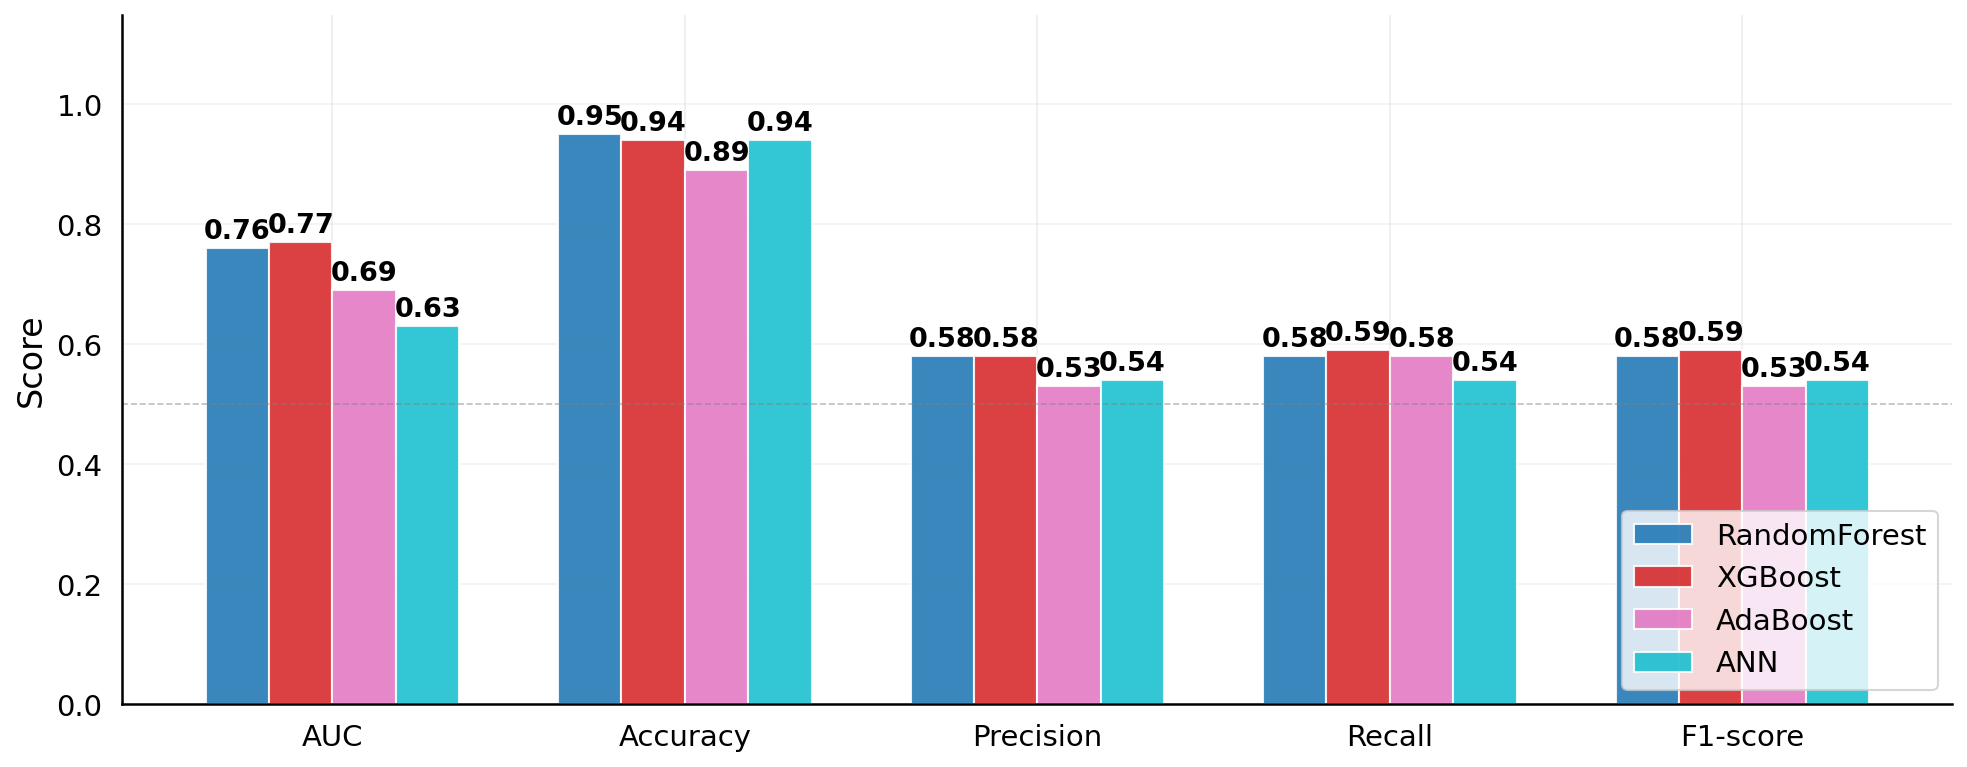


  TRAIN vs TEST — overfitting / leakage check


,AUC (train),AUC (test),AUC gap (train-test),F1-score (train),F1-score (test),F1-score gap (train-test)
Model,,,,,,
RandomForest,0.78,0.76,0.02,0.49,0.49,0.00
XGBoost,0.77,0.77,0.00,0.48,0.48,0.00
AdaBoost,0.69,0.69,0.00,0.52,0.52,0.00
ANN,0.66,0.63,0.04,0.56,0.54,0.02


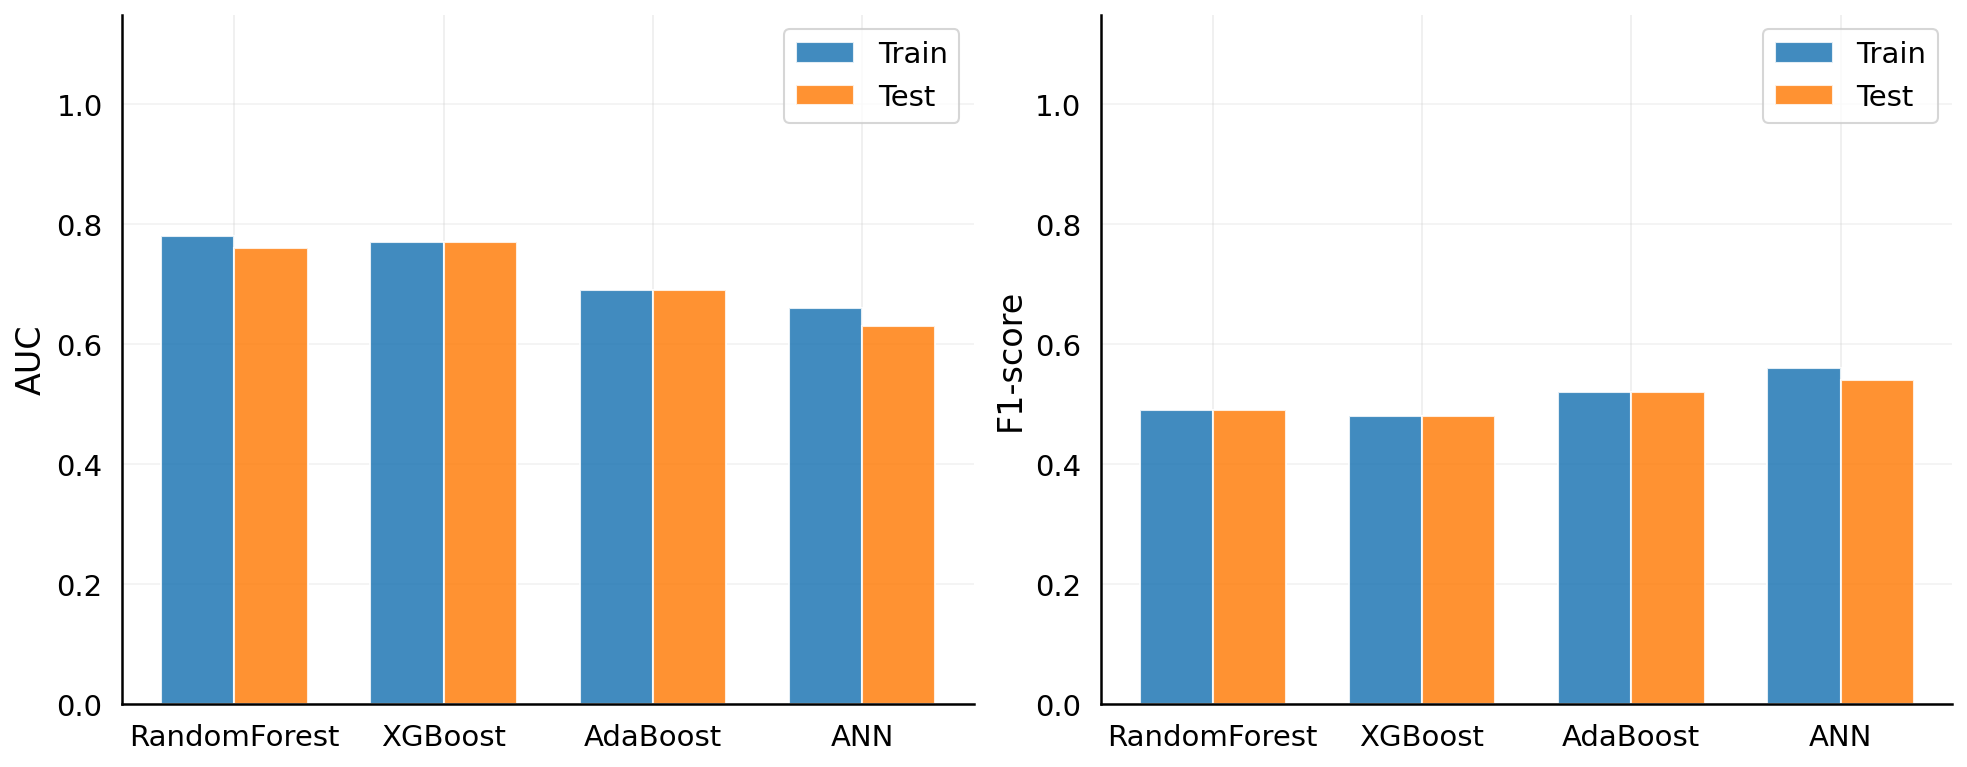

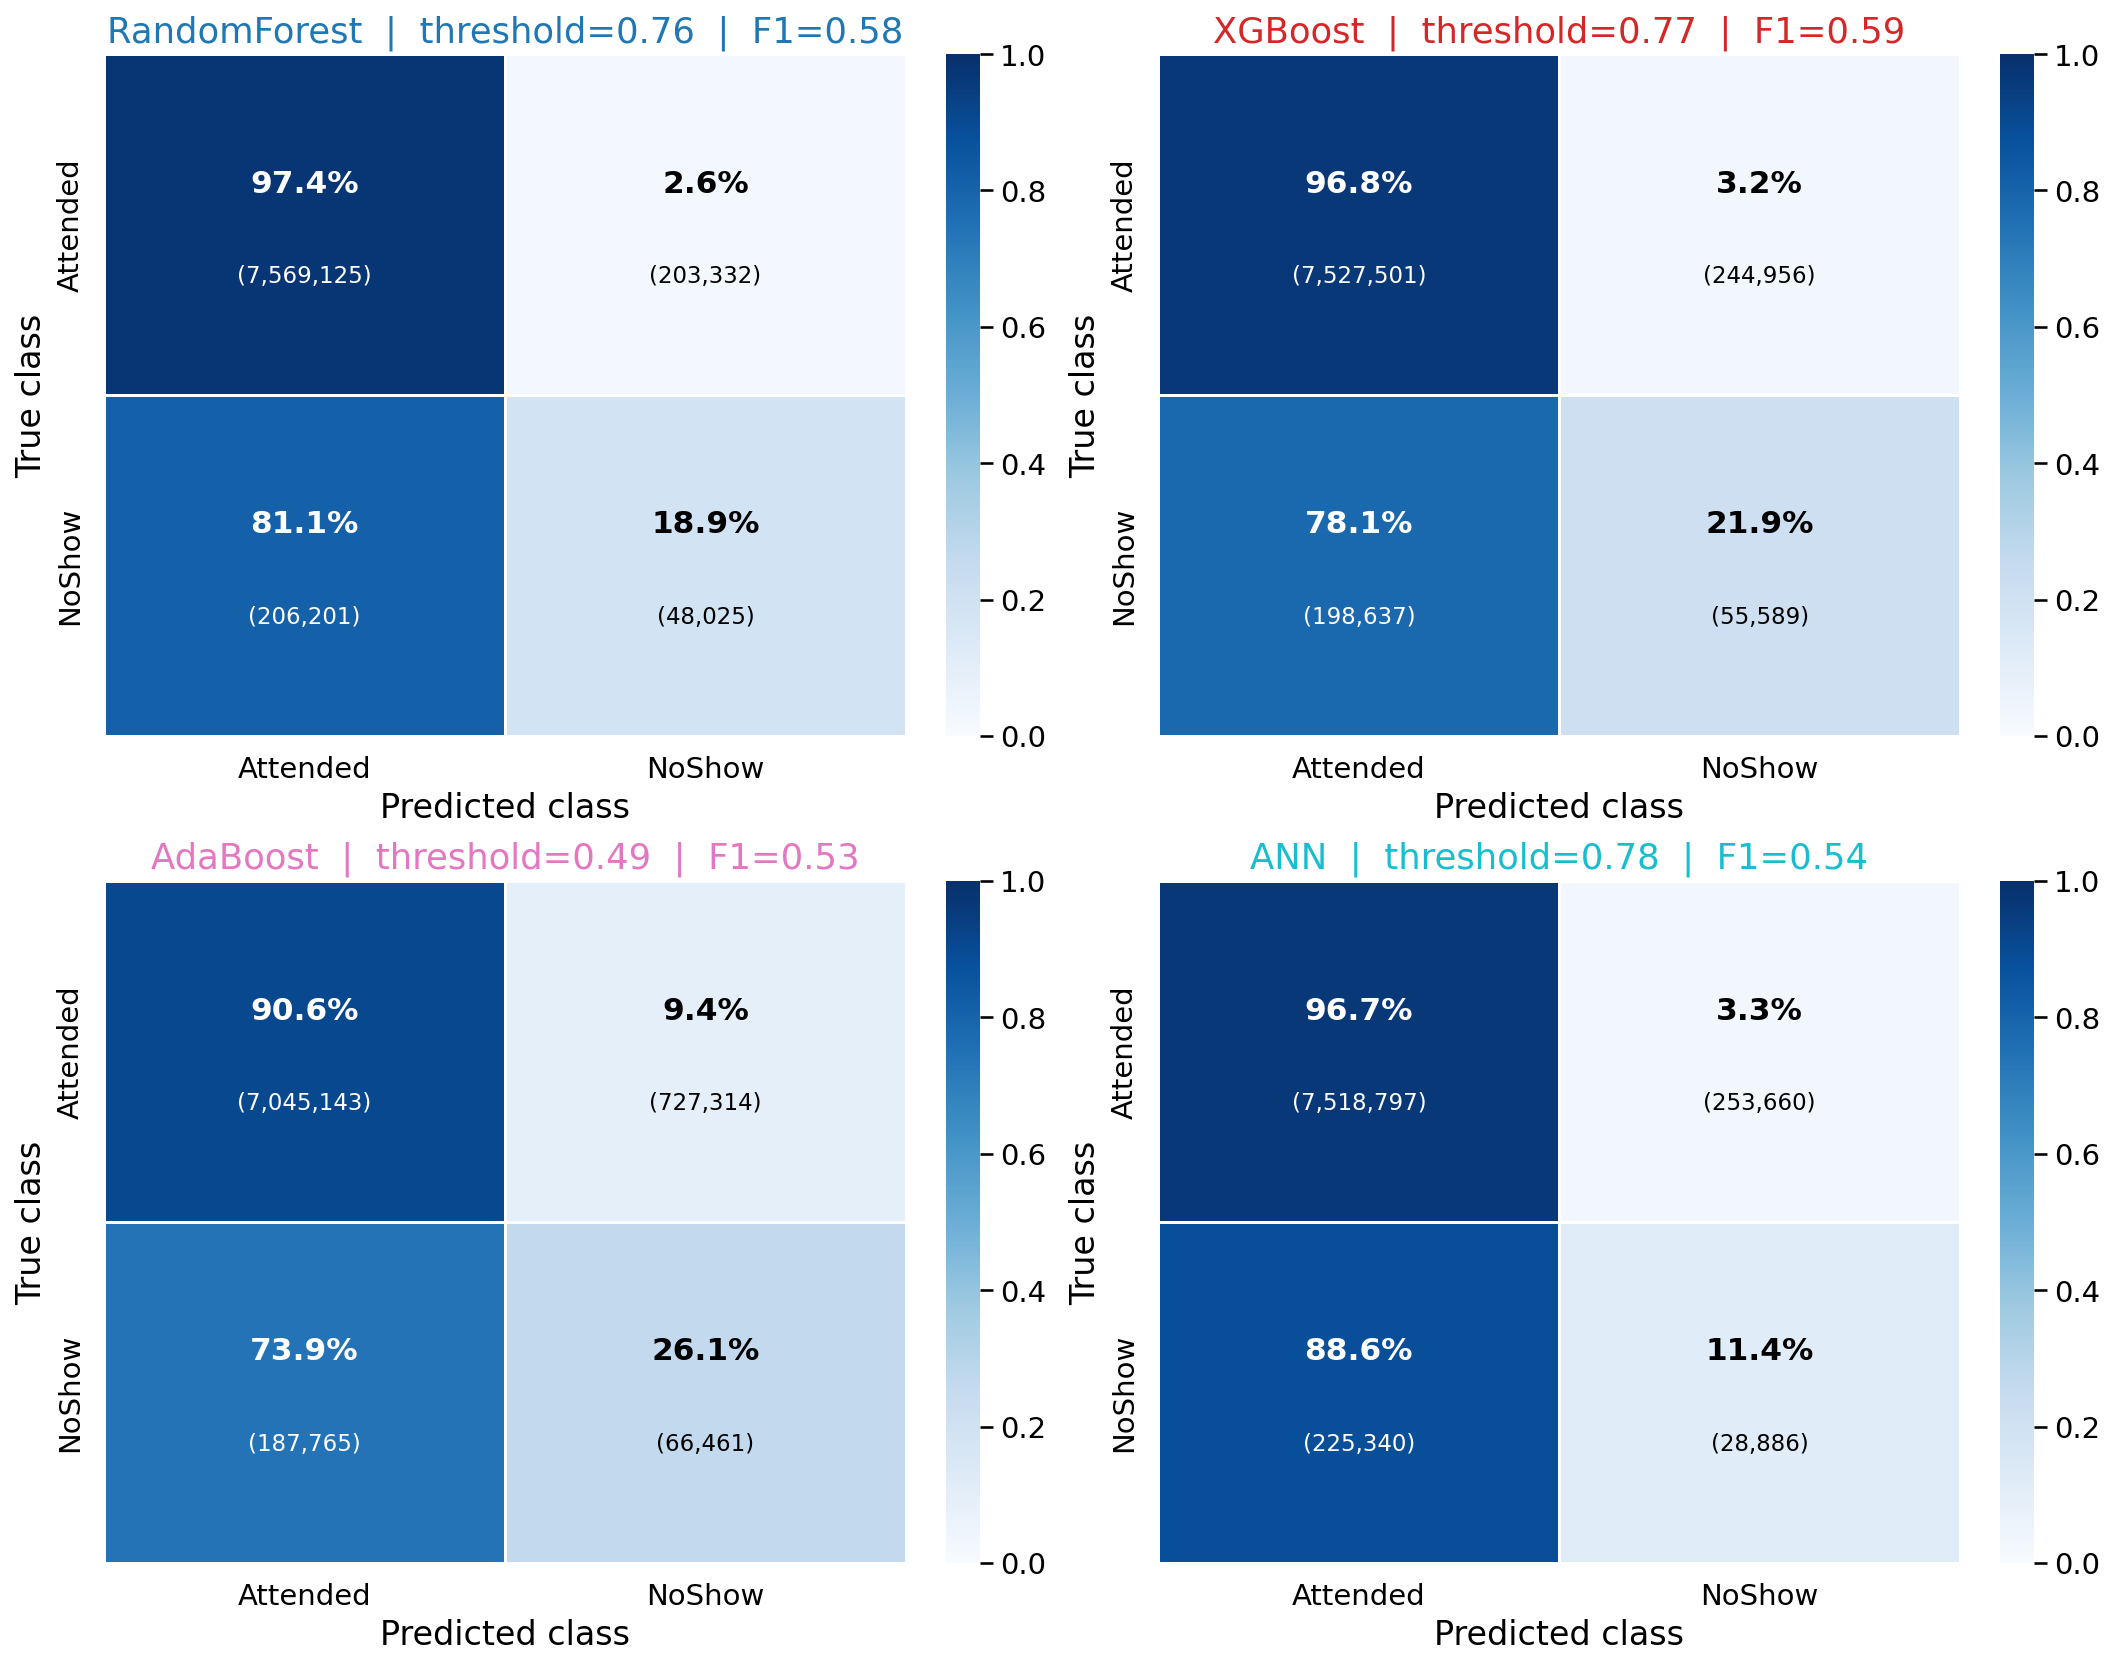

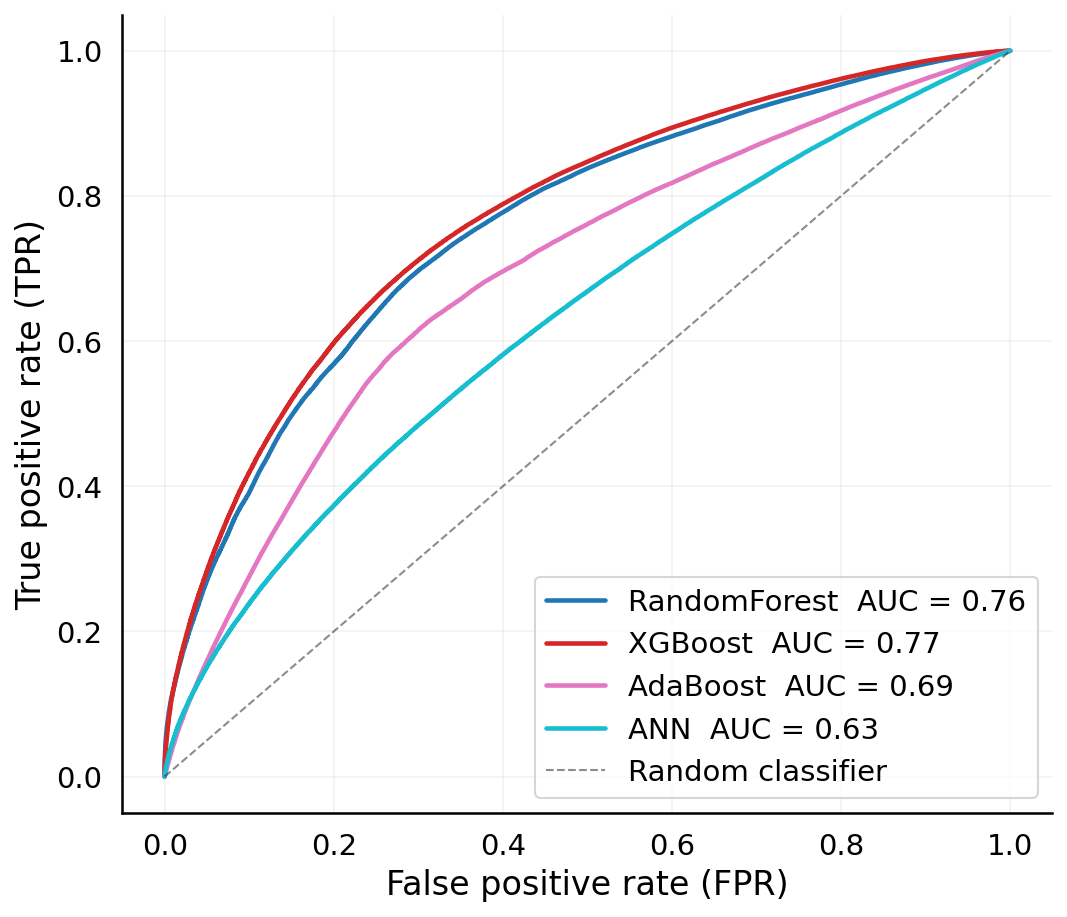

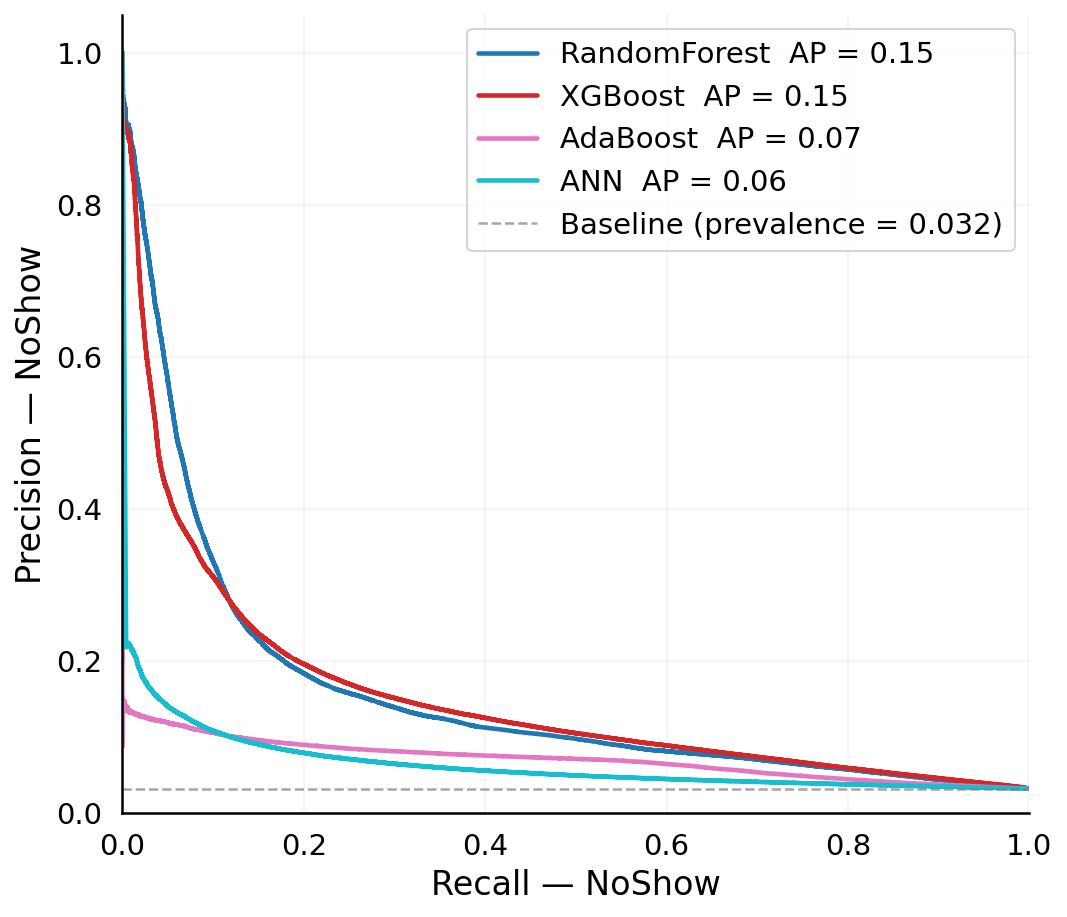

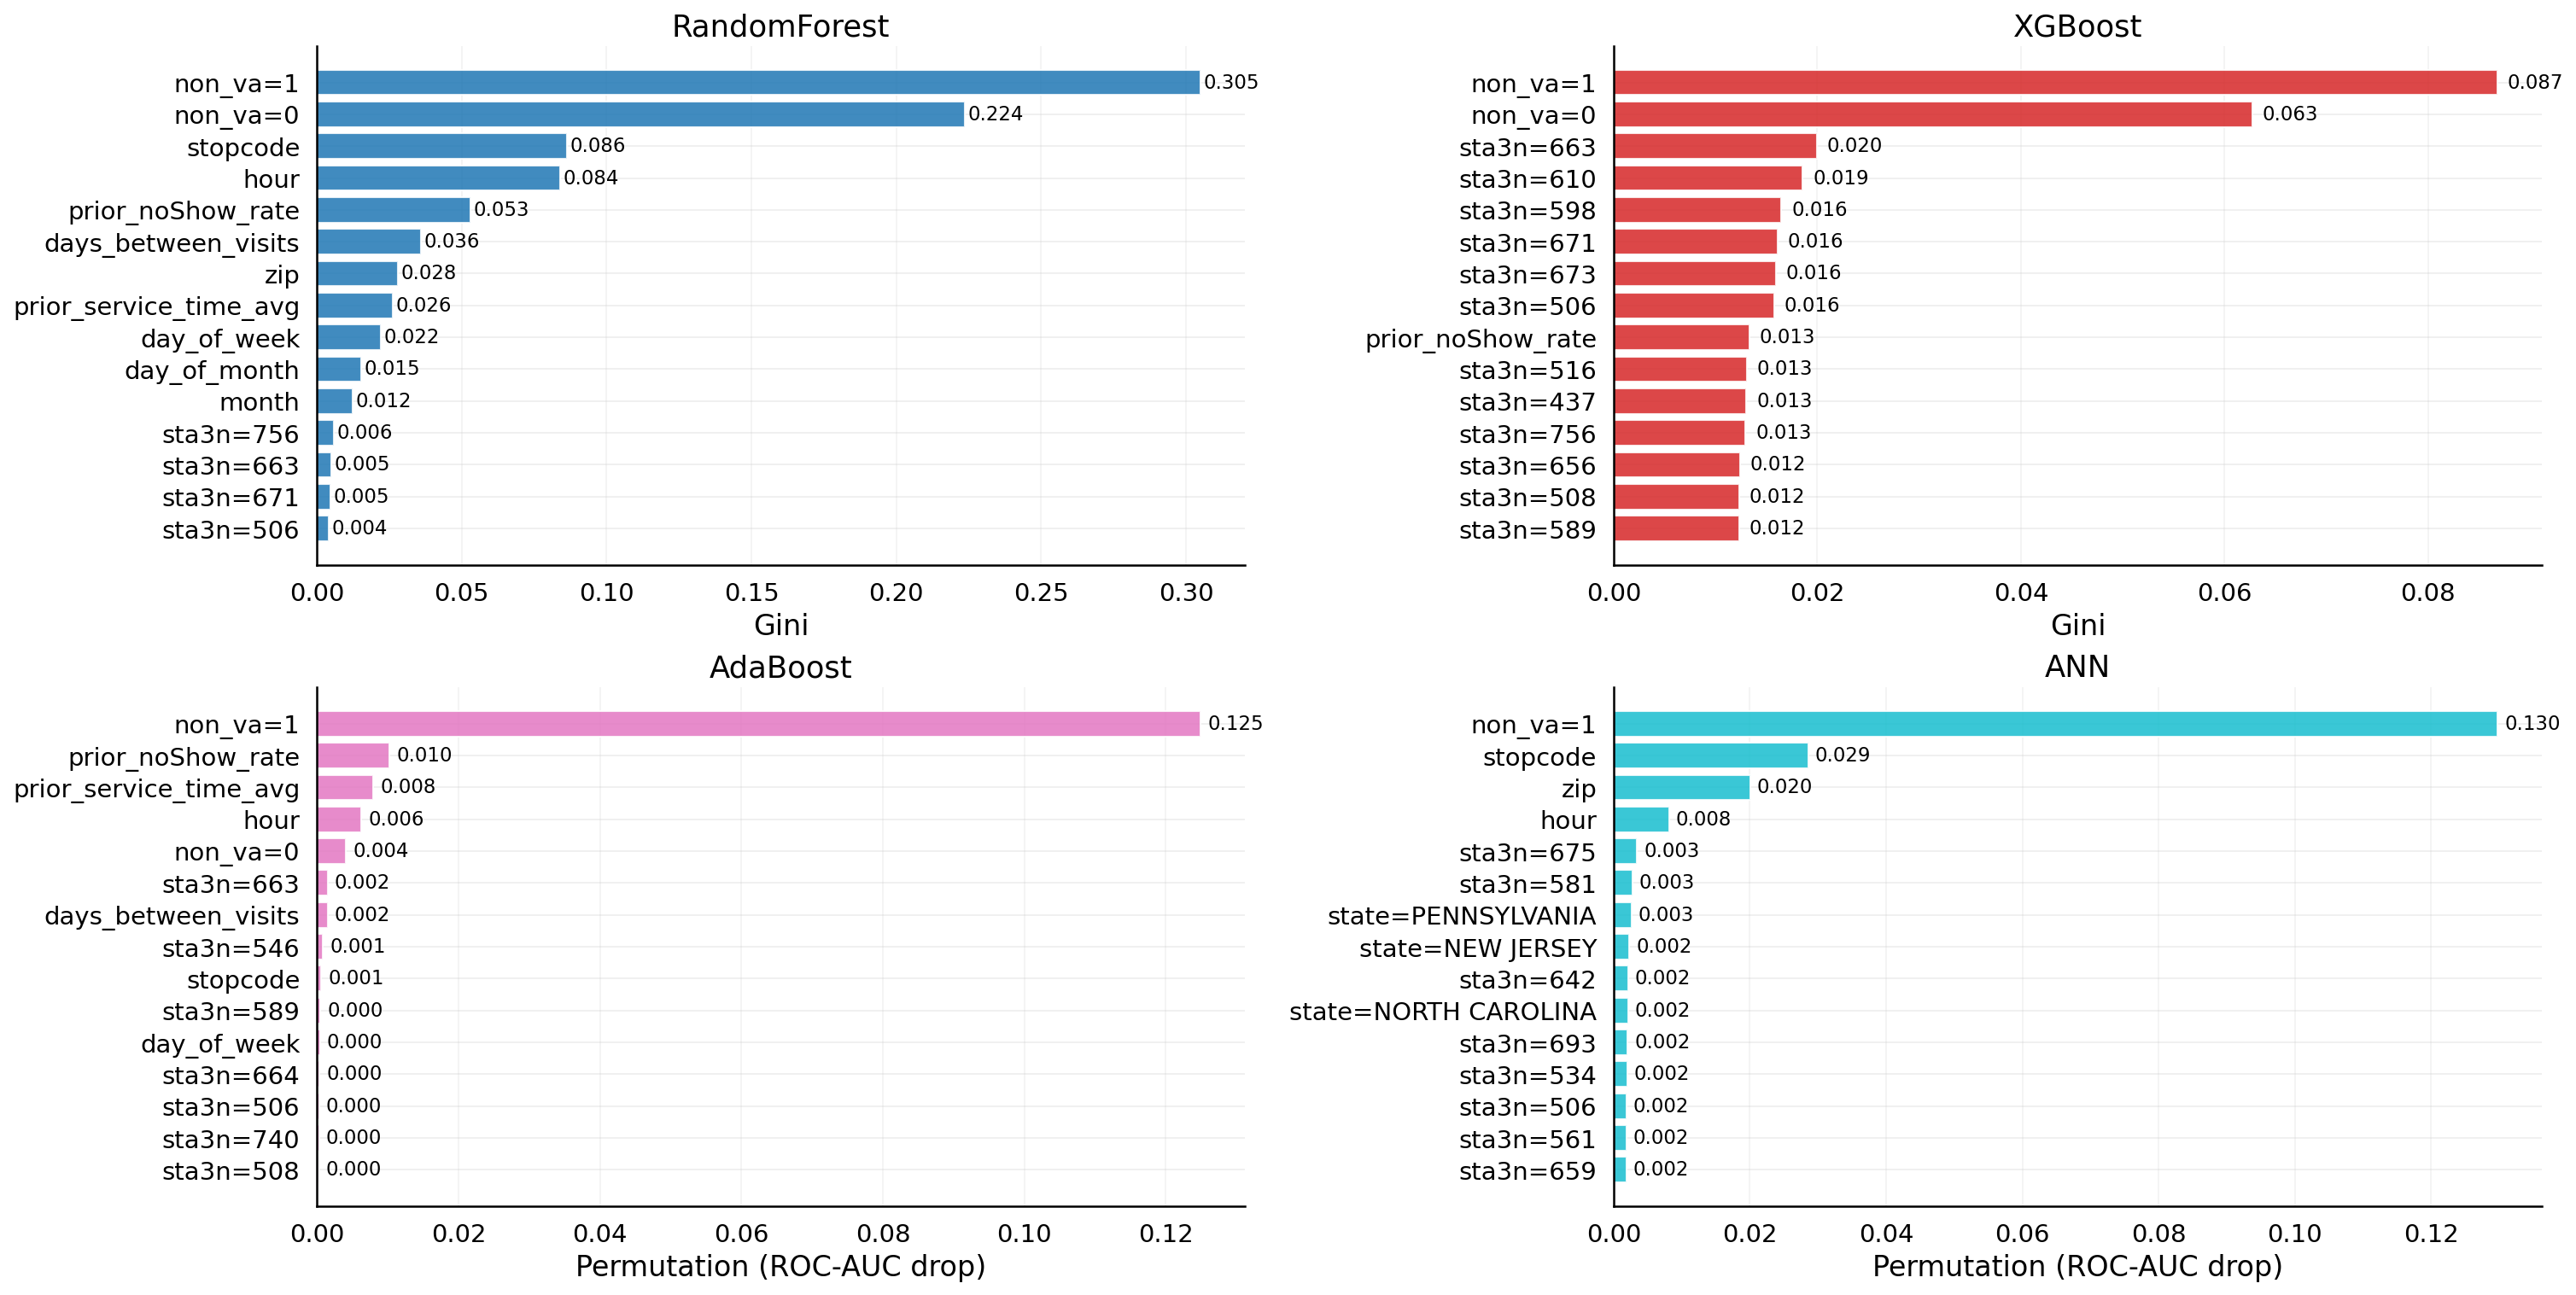

In [23]:
# ── 4a. Comparative evaluation (+ train vs test overfitting check) ───────────
# config=... : the decision threshold follows the configuration's threshold_metric.
# plots=[...] : restricting the figures speeds up tuning iterations
#   (e.g. plots=["metrics"]); eval_sample=200_000 evaluates on a test extract.
results_noshow = evaluate_binary_classification_models(
    noshow_models, X_test, y_test_ns, positive_name="NoShow", reference_name="Attended",
    feature_cols=feature_cols, X_train=X_fit_ns, y_tr=y_fit_ns, prefix="noshow",
    config=TRAIN_CFG_NOSHOW, plots=ALL_EVAL_PLOTS, perm_sample=20_000, eval_sample=None,
)


In [24]:
# ── 4a. Record the run (to compare successive settings) ─────────────────────
# Rename the label for each run: it is the lookup key in the comparison table
# of section 4c.
record_training_run("no-show — reference config", results_noshow, TRAIN_CFG_NOSHOW,
                    notes="grid / roc_auc / SMOTE / f1_macro threshold")


,Run,Model,search,scoring,cv,fit_sample,smote,balance,threshold,AUC,Accuracy,Precision,Recall,F1-score,Threshold,Notes
0,no-show — reference config,XGBoost,random,f1_macro,3,2000000,True,True,f1_macro,0.77,0.94,0.58,0.59,0.59,0.77,grid / roc_auc / SMOTE / f1_macro threshold
1,no-show — reference config,RandomForest,random,f1_macro,3,2000000,True,True,f1_macro,0.76,0.95,0.58,0.58,0.58,0.76,grid / roc_auc / SMOTE / f1_macro threshold
2,no-show — reference config,AdaBoost,random,f1_macro,3,2000000,True,True,f1_macro,0.69,0.89,0.53,0.58,0.53,0.49,grid / roc_auc / SMOTE / f1_macro threshold
3,no-show — reference config,ANN,random,f1_macro,3,2000000,True,True,f1_macro,0.63,0.94,0.54,0.54,0.54,0.78,grid / roc_auc / SMOTE / f1_macro threshold


### 4b. Service time — clustering then classification

**K-means (K=2):** validated by the elbow method (SAE) and the silhouette coefficient on a 200k-row sample, confirmed by bootstrap (silhouette stability across resamples).

The clustering parameters (candidate K, sample size, bootstrap) are gathered in the cell below, like the training ones.

In [25]:
# ── 4b. Clustering settings ───────────────────────────────────────────────────
CLUSTER_KS = [2, 3, 4, 5]     # values of K compared (elbow + silhouette)
CLUSTER_SAMPLE = 200_000      # rows used to evaluate K
N_BOOTSTRAP = 10              # resamples validating the silhouette
BOOTSTRAP_SAMPLE = 10_000     # size of each resample
KMEANS_N_INIT = 10            # K-means restarts (solution stability)
FORCE_K = None                # impose K (e.g. 2) instead of the maximum silhouette


KMeans clustering


  K=2 | SAE=88442.34 | Silhouette=0.6949


  K=3 | SAE=63047.54 | Silhouette=0.6306


  K=4 | SAE=50639.58 | Silhouette=0.6161


  K=5 | SAE=43986.93 | Silhouette=0.6065


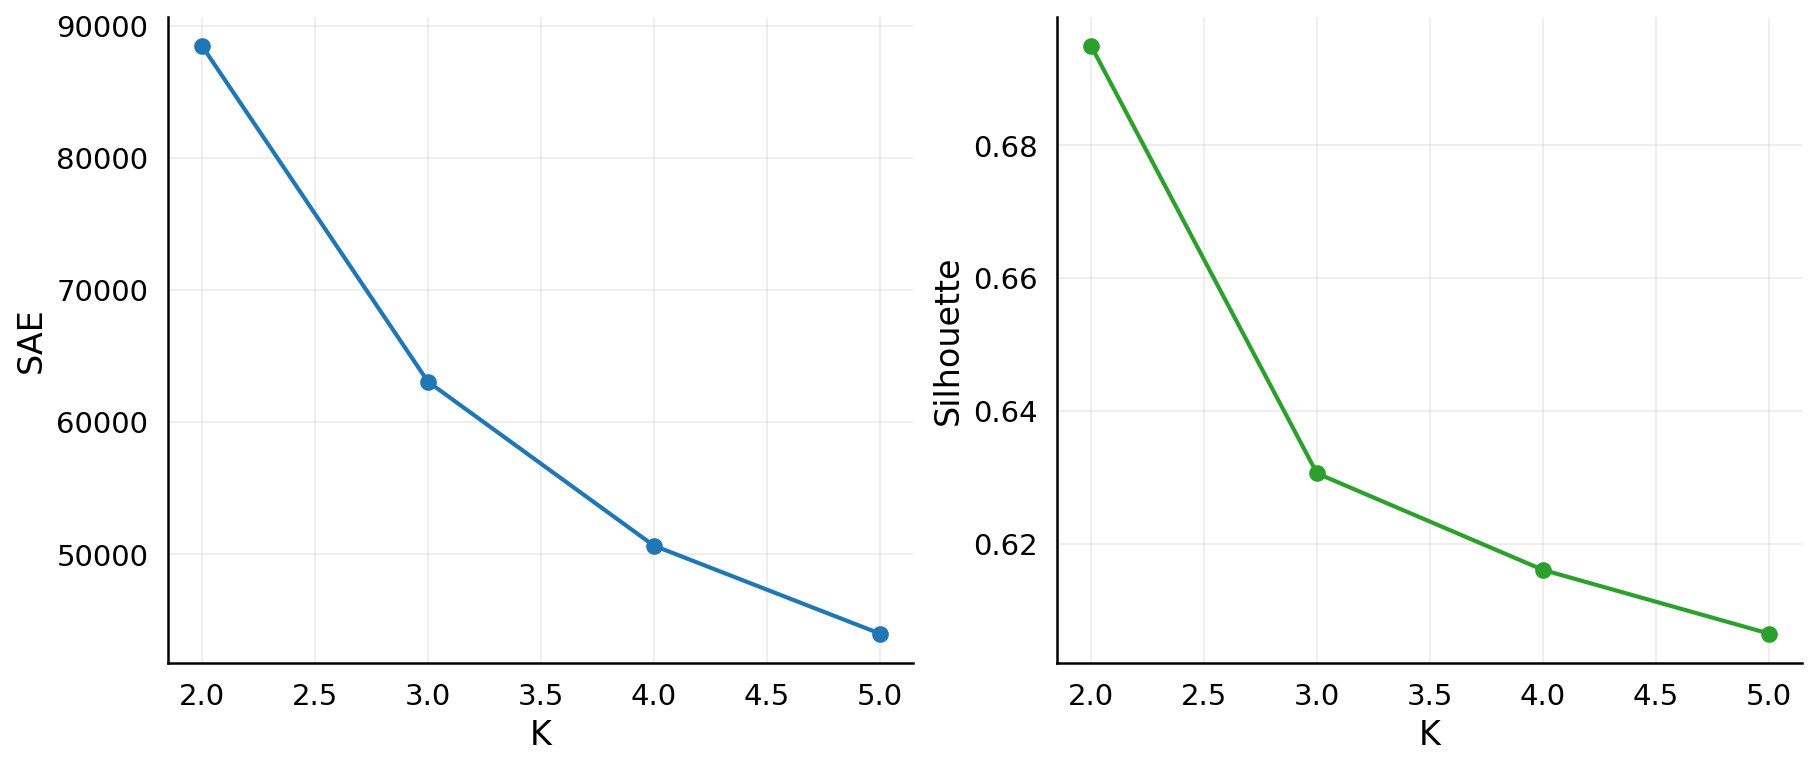

K selected (maximum silhouette): 2


In [26]:
# ── 4b. Selecting K (elbow + silhouette) ──────────────────────────────────────
sae_results, sil_results, service_time_std, cluster_scaler = evaluate_clustering_ks(
    df_sample, service_time_col="service_time", candidate_ks=CLUSTER_KS,
    sample_size=CLUSTER_SAMPLE, random_state=RANDOM_STATE,
)
best_k = FORCE_K or max(sil_results, key=sil_results.get)
print(f"K selected ({'imposed' if FORCE_K else 'maximum silhouette'}): {best_k}")


In [27]:
# ── 4b. Bootstrap validation + A/B labelling ──────────────────────────────────
from sklearn.cluster import KMeans as _KMeans
_labels_full = _KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=KMEANS_N_INIT).fit_predict(service_time_std)
mu_sil, sd_sil = bootstrap_silhouette(service_time_std, _labels_full,
                                      n_bootstrap=N_BOOTSTRAP, sample_size=BOOTSTRAP_SAMPLE)
print(f"Bootstrapped silhouette (K={best_k}): mean={mu_sil:.4f}, sd={sd_sil:.4f}")

df_sample, cluster_profile, label_map, label_names = fit_clustering_and_label(
    df_sample, best_k, service_time_std, service_time_col="service_time", random_state=RANDOM_STATE,
)
service_time_by_group = df_sample.groupby("group_label")["service_time"].mean().to_dict()
print("Mean service time per group:", service_time_by_group)


Bootstrapped silhouette (K=2): mean=0.6917, sd=0.0035



Group profile:
            count       mean  median
cluster                             
1         6216643  64.246819    55.0
0        33916770  13.016100    11.0


Mean service time per group: {'A': 64.24681858038173, 'B': 13.01610008854027}


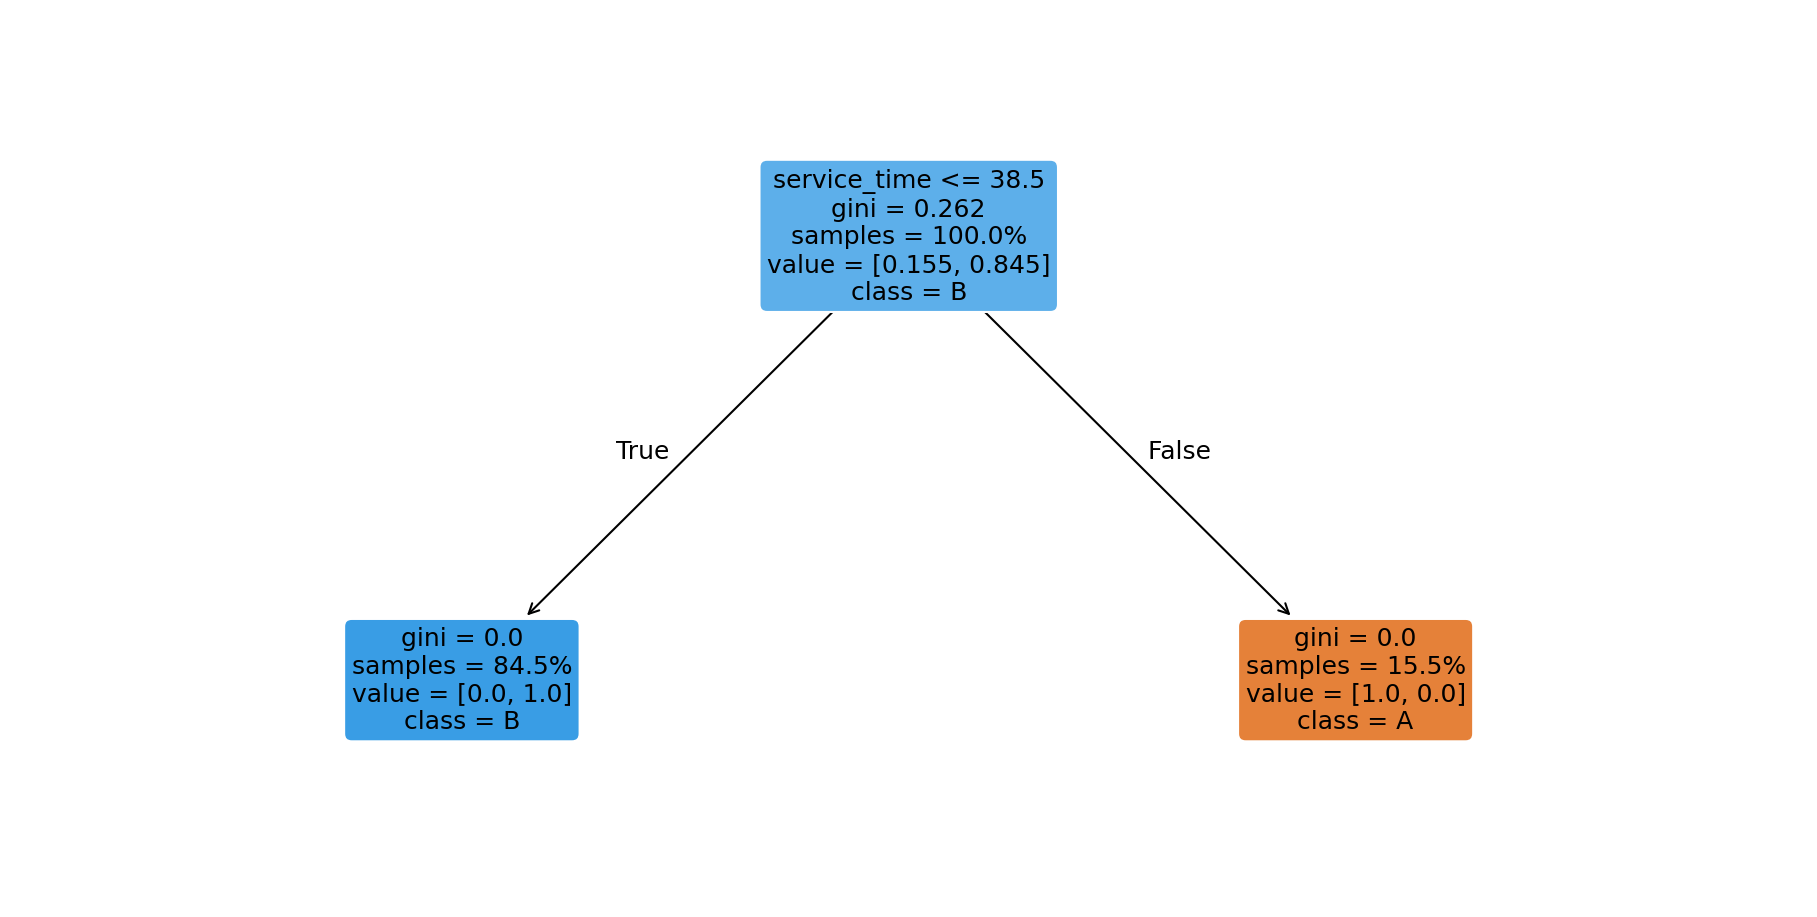


Primary cutoff (tree root): 38.50 min

Final profile per group:


                count       mean  median
group_label                             
A             6216643  64.246819    55.0
B            33916770  13.016100    11.0


In [28]:
# ── 4b. Interpretable cutoff (decision tree) ─────────────────────────────────
cluster_tree, primary_cutoff = learn_decision_tree_cutoffs(
    df_sample, service_time_col="service_time", group_col="group_label", label_names=label_names,
)


**Group classifier.** Same training function, hence the same levers: `TRAIN_CFG_GROUP` starts from the no-show configuration and changes only what needs changing. The A/B target being far less imbalanced than no-show, SMOTE and class weighting matter less here — that is the setting to test first.

In [29]:
# ── 4b. Training settings — A/B group classifier ─────────────────────────────
TRAIN_CFG_GROUP = TRAIN_CFG_NOSHOW.replace(
    # e.g. models=["XGBoost", "RandomForest"], use_smote=False, scoring="f1_macro"
)
display(TRAIN_CFG_GROUP.summary())


,Setting,Value
0,Models trained,"RandomForest, XGBoost, AdaBoost, ANN"
1,Hyperparameter search,random (n_iter=12)
2,Cross-validation folds (cv),3
3,Optimised score,f1_macro
4,Tuning subsample,"40,000"
5,Fit subsample,"2,000,000"
6,SMOTE (tuning),yes {}
7,Class weighting,yes
8,scale_pos_weight (XGB),auto
9,Threshold criterion,f1_macro


In [30]:
# ── 4b. Group assignment classifier for new patients ─────────────────────────
y_train_grp, y_test_grp = get_group_labels_for_split(df_sample, X_train, X_test)
group_models, y_train_grp_bin, y_test_grp_bin, X_fit_grp, y_fit_grp = train_binary_classifiers(
    X_train, y_train_grp, X_test, y_test_grp,
    feature_cols, positive_label="A", config=TRAIN_CFG_GROUP,
)
display(group_models.search_report)


Train distribution: {'B': 23742187, 'A': 4351202}
Test distribution : {'B': 6782704, 'A': 1243979}


Positive class (of interest) 'A': 4,351,202  |  reference: 23,742,187
scale_pos_weight (XGB): 5.46


Fit subsample: 2,000,000 / 28,093,389 rows


Tuning subsample: 40,000 rows  |  search: random (cv=3, scoring=f1_macro)
Class rebalancing: class weights (ANN: SMOTE inside its pipeline)

--- RandomForest ---


RandomForest best params: {'n_estimators': 200, 'min_samples_leaf': 20, 'max_features': 0.3, 'max_depth': 16}  | CV f1_macro: 0.5708  (12 candidates, 54.4s)


RandomForest trained on 5,000,000 rows in 630.6s

--- XGBoost ---


... (3 outputs left out)

AdaBoost trained on 250,000 rows in 46.4s

--- ANN ---


ANN best params: {'clf__learning_rate_init': 0.0003, 'clf__hidden_layer_sizes': (256, 128), 'clf__alpha': 0.001}  | CV f1_macro: 0.5295  (12 candidates, 173.8s)


ANN trained on 200,000 rows in 571.8s


,Search,Candidates,CV f1_macro,Best params,Fit rows,Search time (s),Fit time (s)
Model,,,,,,,
RandomForest,random,12,0.5708,"{'n_estimators': 200, 'min_samples_leaf': 20, ...",5000000,54.4,630.6
XGBoost,random,12,0.5627,"{'subsample': 0.8, 'reg_lambda': 1.0, 'n_estim...",28093389,22.7,288.3
AdaBoost,random,4,0.5310,"{'clf__n_estimators': 100, 'clf__learning_rate...",250000,34.3,46.4
ANN,random,12,0.5295,"{'clf__learning_rate_init': 0.0003, 'clf__hidd...",200000,173.8,571.8


In [31]:
# ── 4b. Save the training state (resume without retraining) ─────────────────
save_model_bundle(
    {"models": group_models, "y_train": y_train_grp_bin, "y_test": y_test_grp_bin,
     "X_fit": X_fit_grp, "y_fit": y_fit_grp, "config": TRAIN_CFG_GROUP},
    name="group_training_state",
)


Saved -> models/group_training_state.joblib  (['models', 'y_train', 'y_test', 'X_fit', 'y_fit', 'config'])


**Fast resume point (optional):** same logic as in 4a — to skip retraining when resuming, do NOT run the training cell above: uncomment and run this one instead.

In [32]:
# ── 4b. Fast resume: reload the models instead of retraining ────────────────
# _state_grp = load_model_bundle("group_training_state")
# group_models, y_train_grp_bin, y_test_grp_bin, X_fit_grp, y_fit_grp = (
#     _state_grp["models"], _state_grp["y_train"], _state_grp["y_test"],
#     _state_grp["X_fit"], _state_grp["y_fit"])
# TRAIN_CFG_GROUP = _state_grp.get("config", TRAIN_CFG_GROUP)



  RESULTS — Group A (long) vs Group B (short)   (threshold optimised on: f1_macro)


,AUC,Accuracy,Precision,Recall,F1-score,Threshold
Model,,,,,,
RandomForest,0.72,0.79,0.61,0.62,0.61,0.59
XGBoost,0.73,0.79,0.61,0.62,0.62,0.61
AdaBoost,0.60,0.79,0.55,0.54,0.54,0.50
ANN,0.63,0.75,0.56,0.57,0.56,0.59


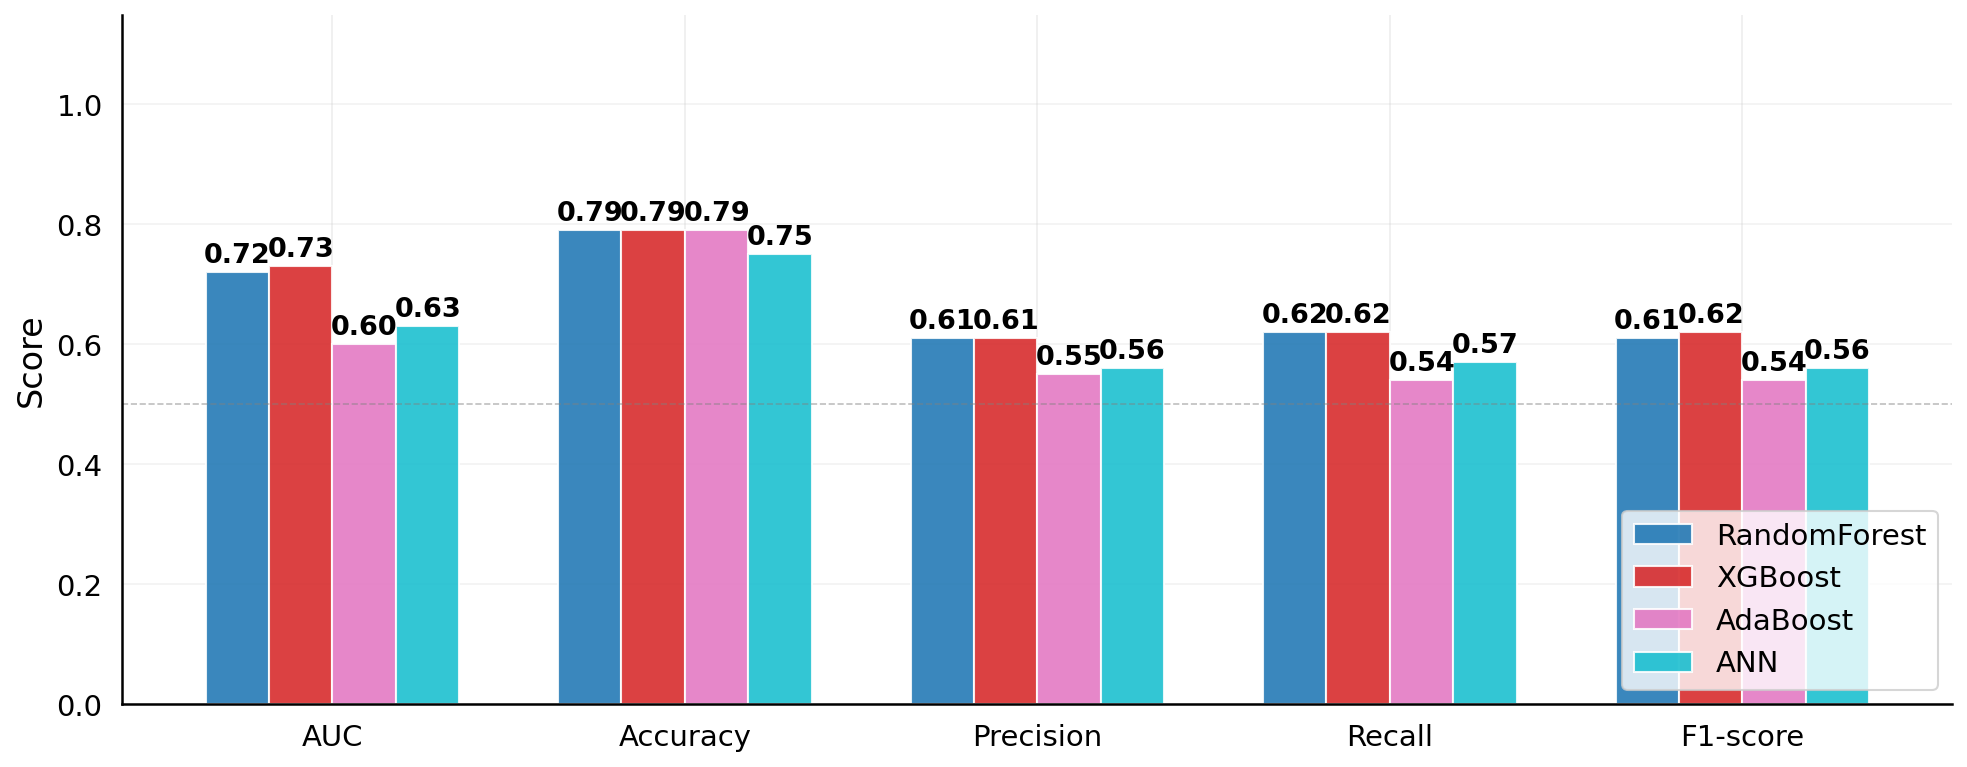


  TRAIN vs TEST — overfitting / leakage check


,AUC (train),AUC (test),AUC gap (train-test),F1-score (train),F1-score (test),F1-score gap (train-test)
Model,,,,,,
RandomForest,0.73,0.72,0.01,0.56,0.55,0.01
XGBoost,0.73,0.73,0.00,0.56,0.56,0.00
AdaBoost,0.60,0.60,0.00,0.54,0.54,0.00
ANN,0.65,0.63,0.01,0.56,0.56,0.01


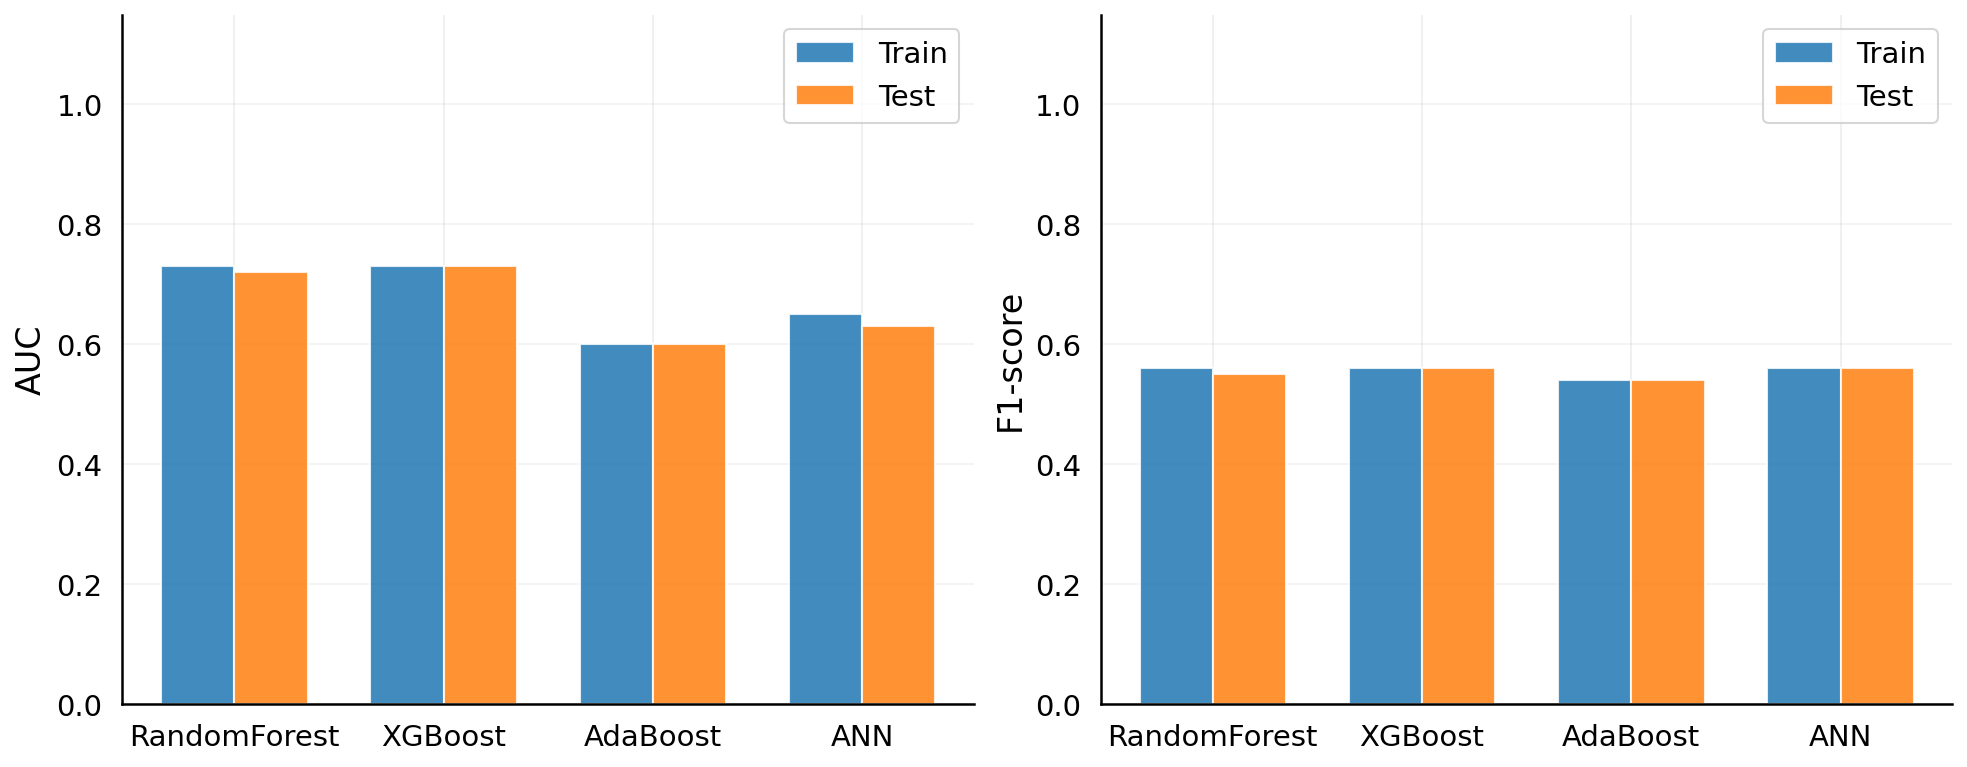

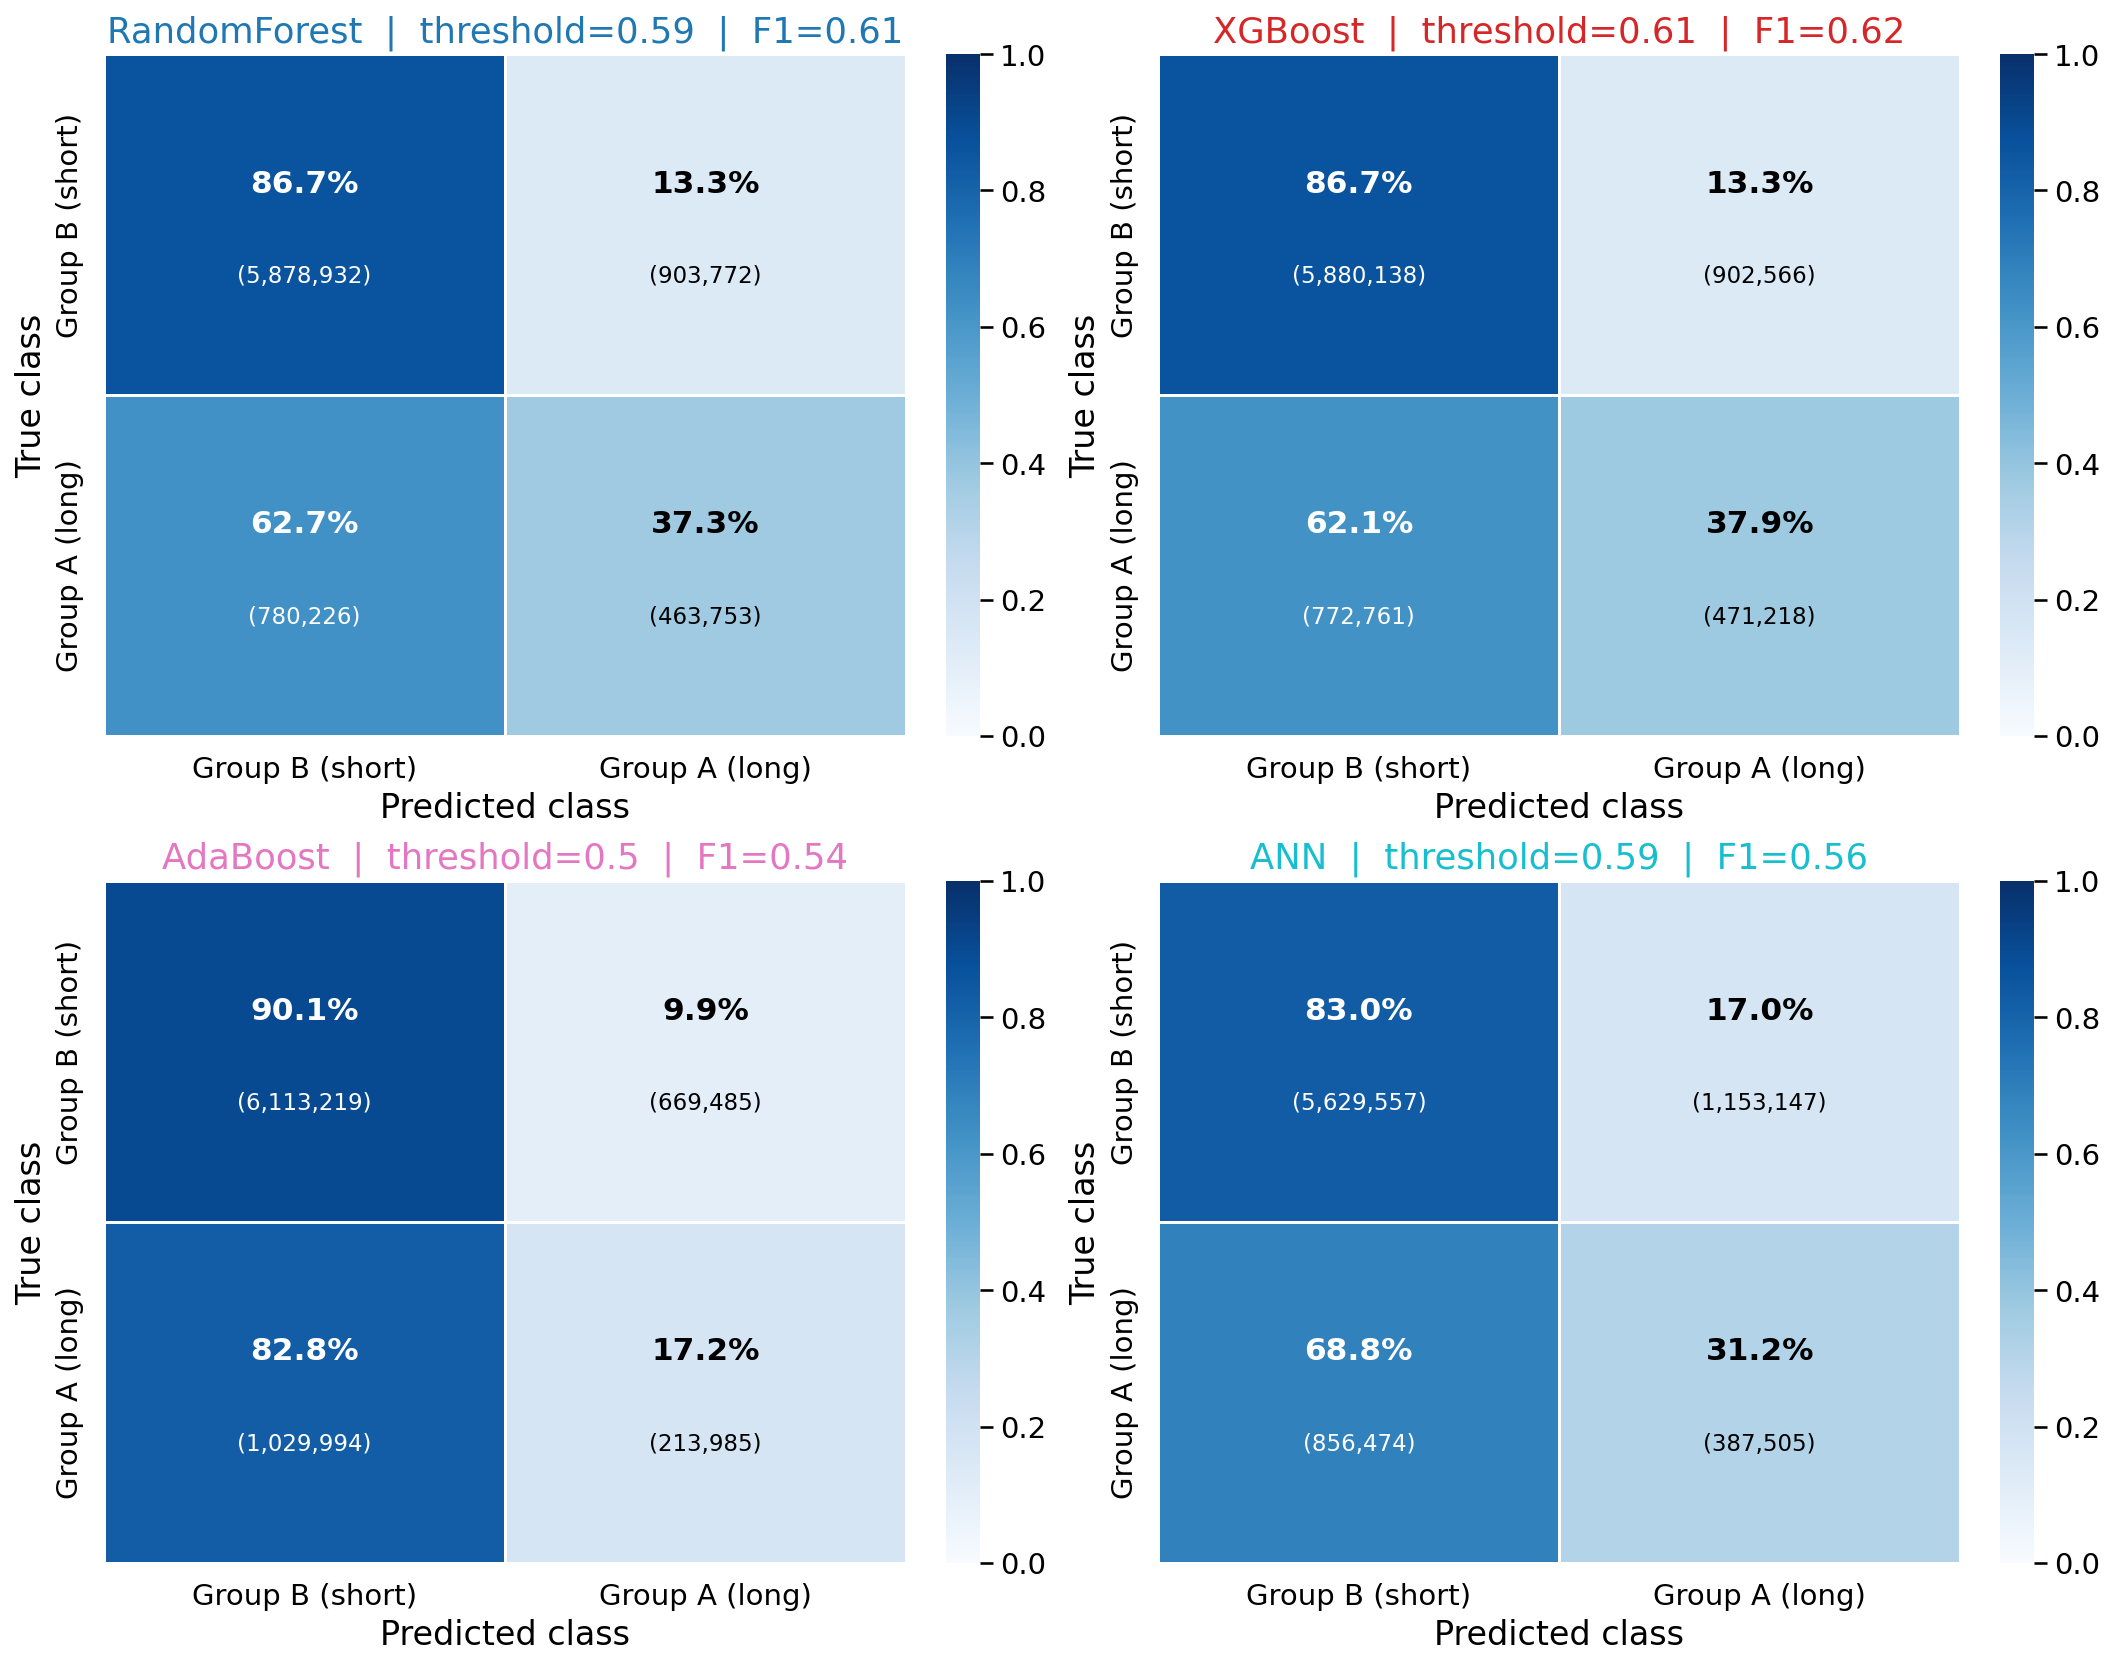

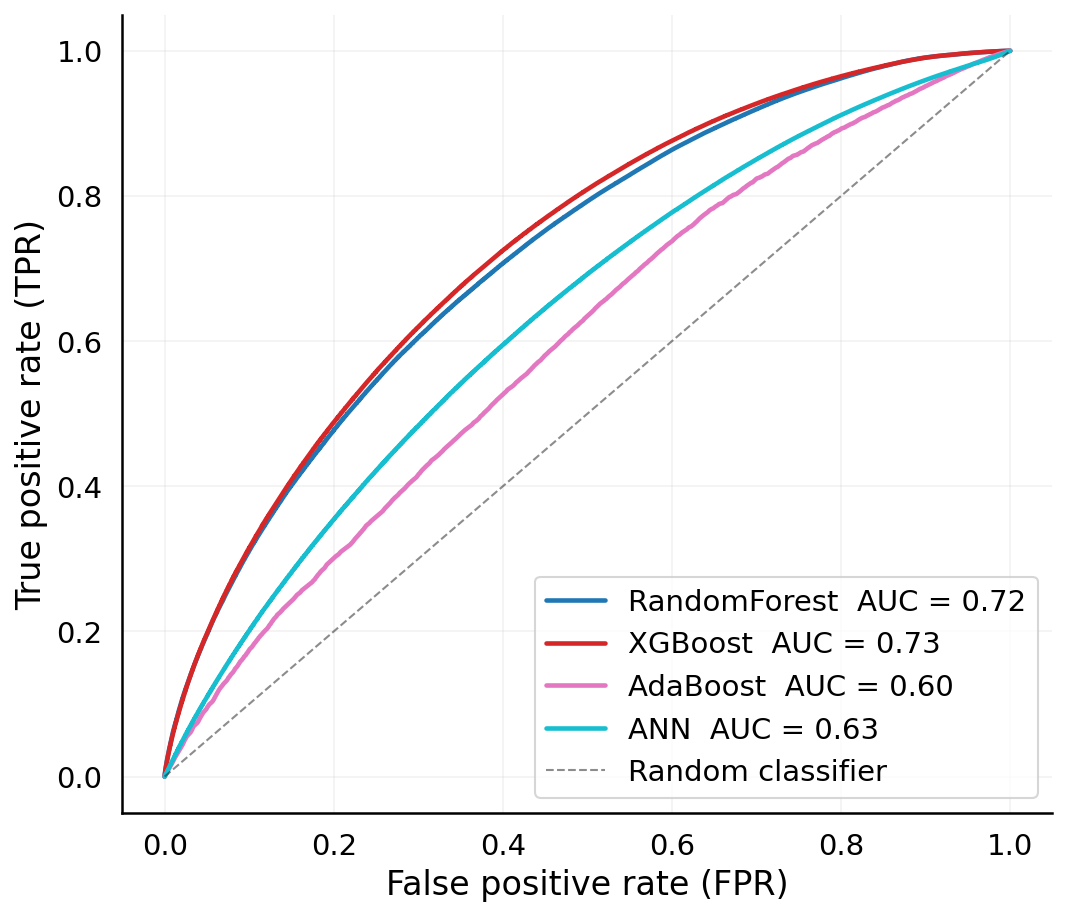

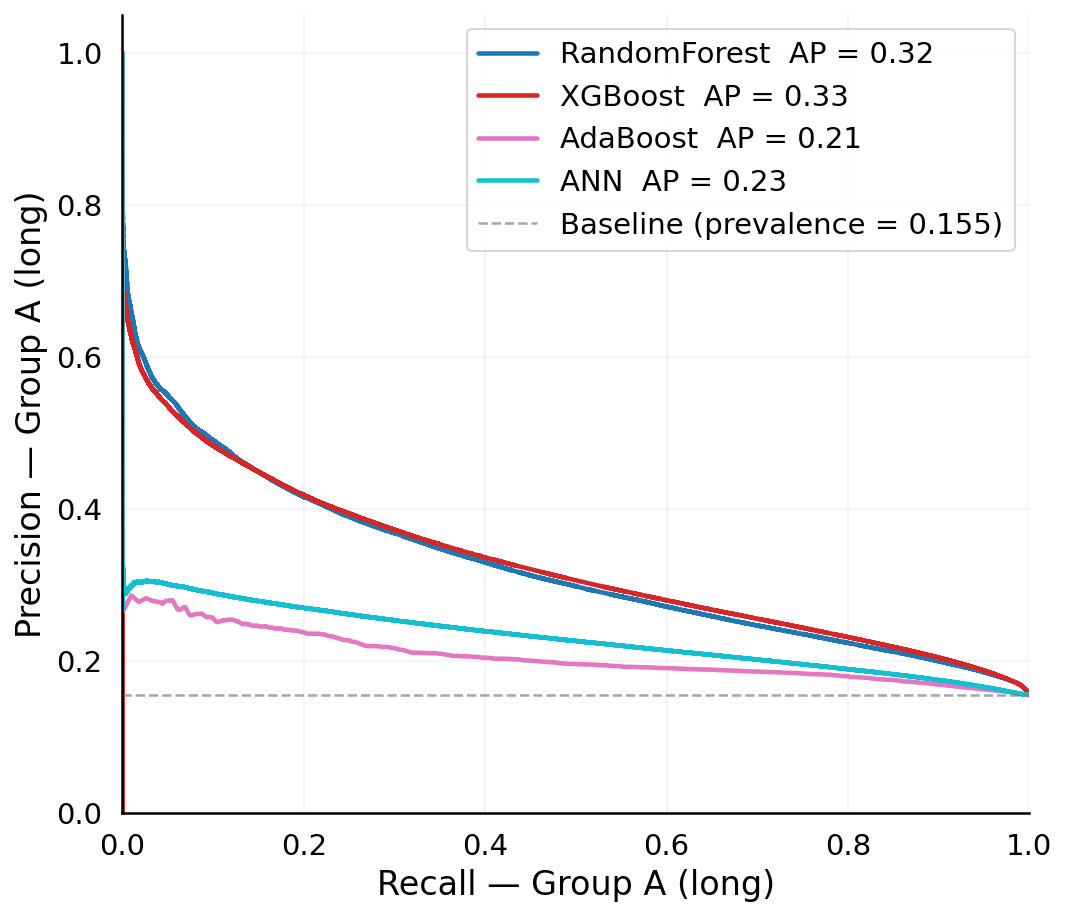

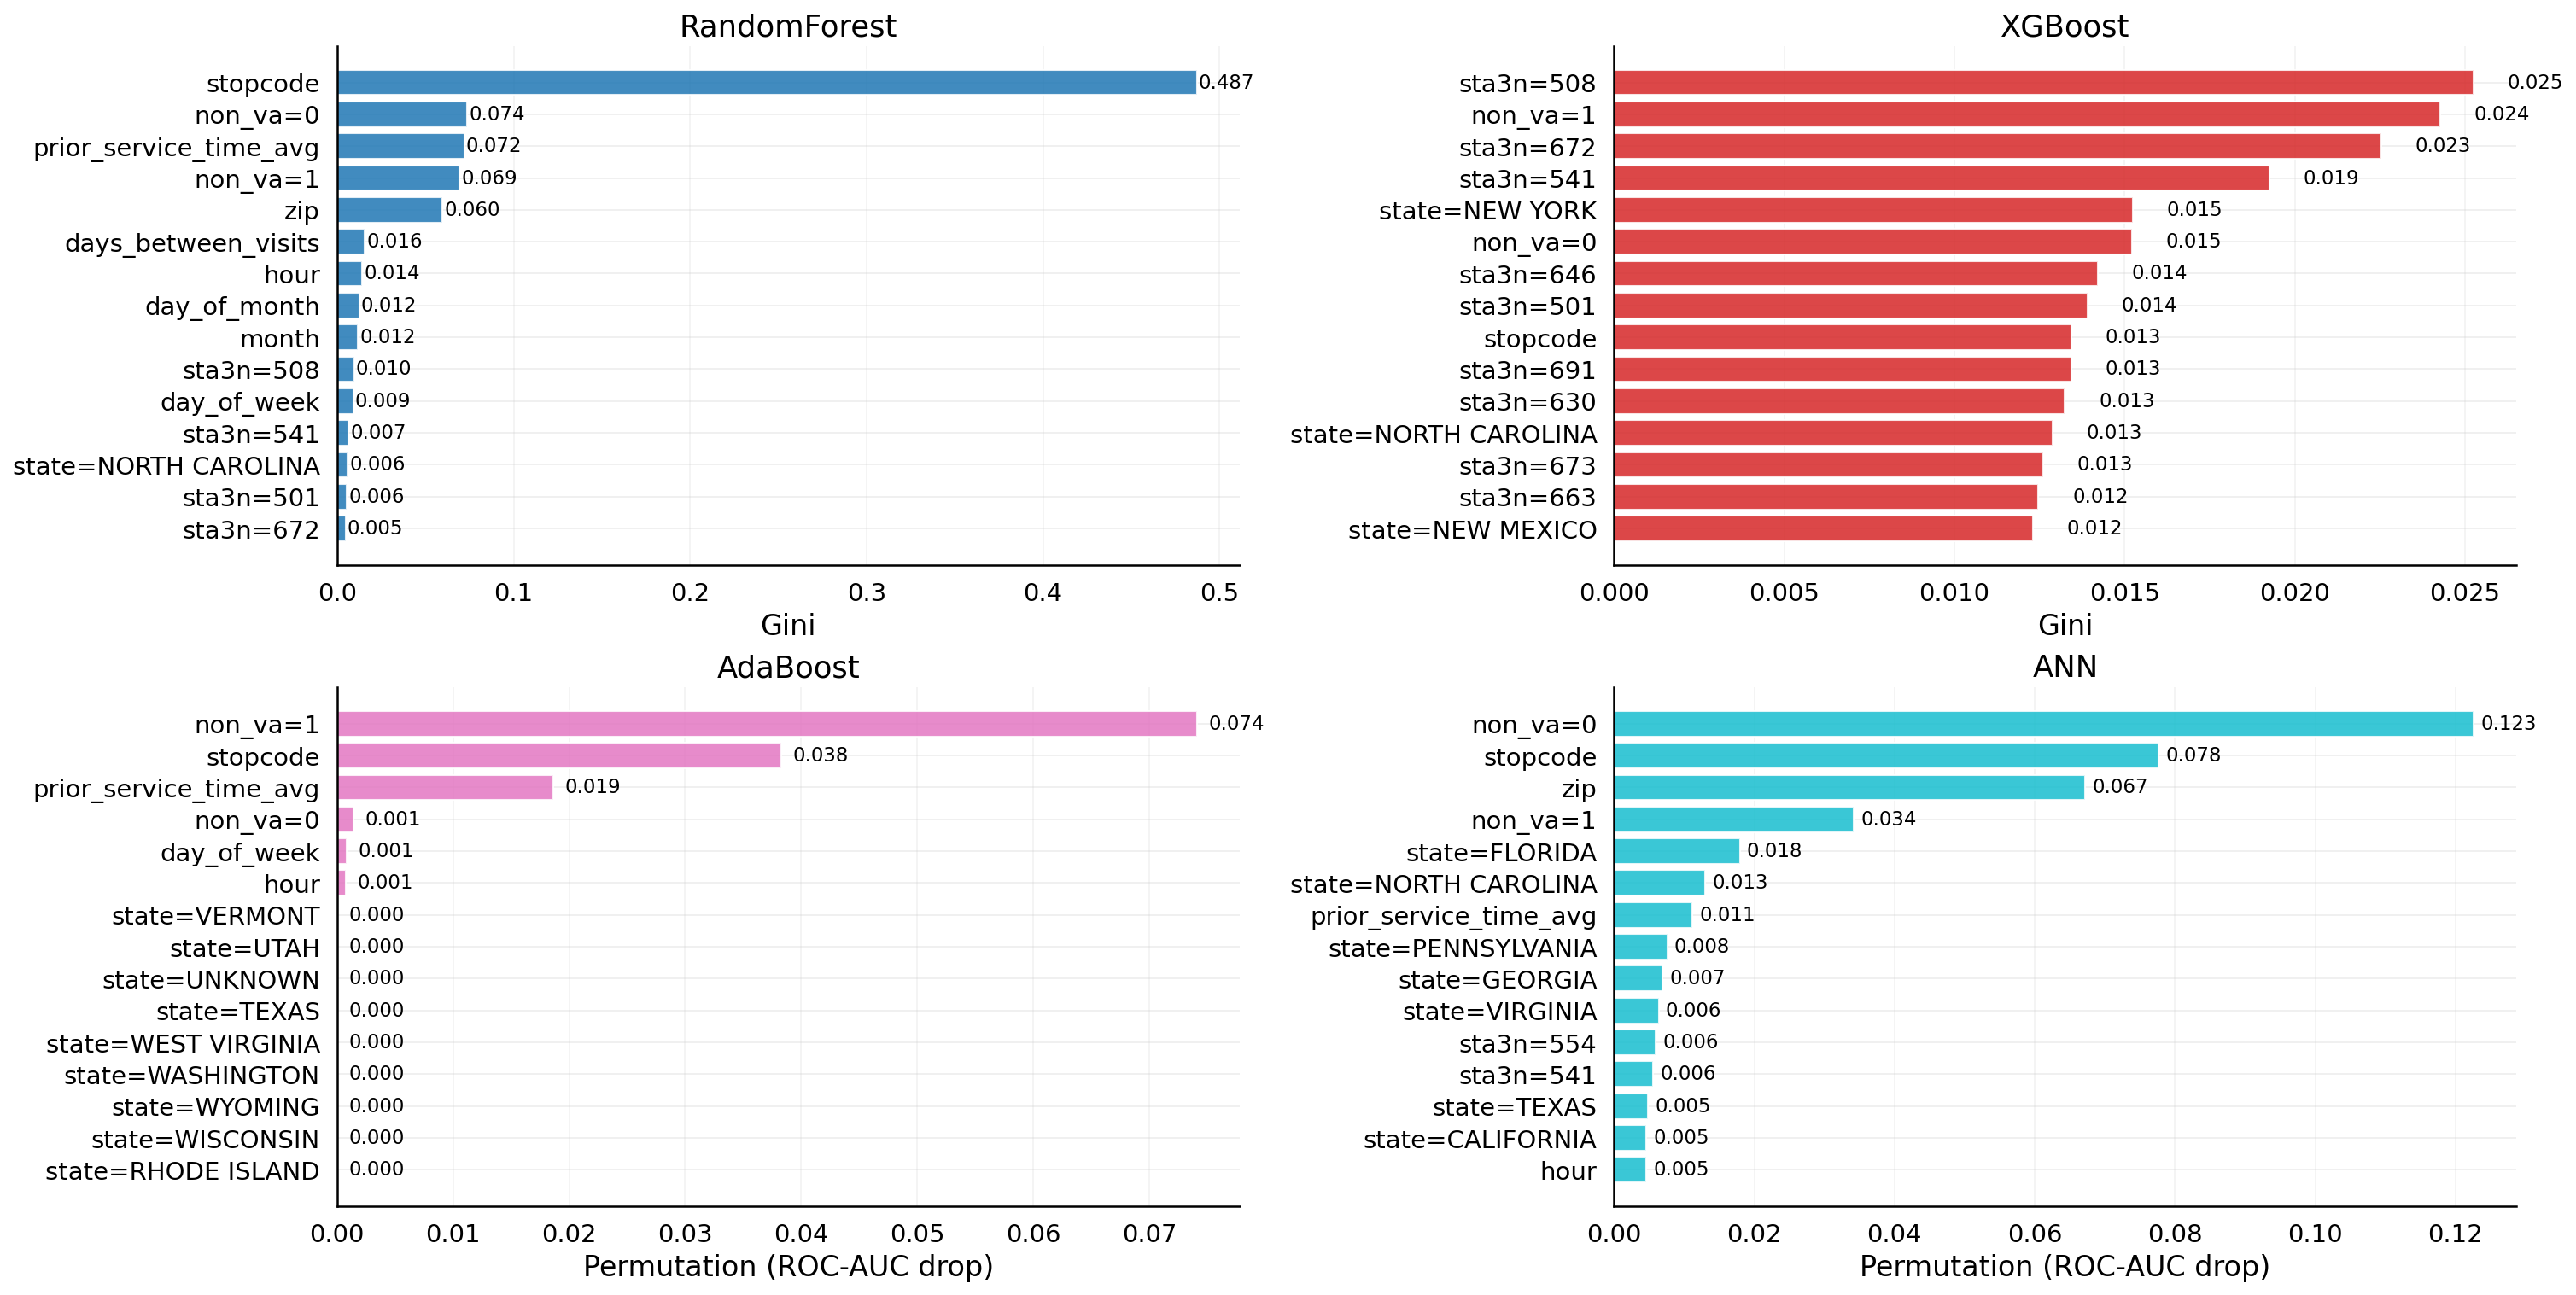

,Run,Model,search,scoring,cv,fit_sample,smote,balance,threshold,AUC,Accuracy,Precision,Recall,F1-score,Threshold,Notes
0,no-show — reference config,XGBoost,random,f1_macro,3,2000000,True,True,f1_macro,0.77,0.94,0.58,0.59,0.59,0.77,grid / roc_auc / SMOTE / f1_macro threshold
1,no-show — reference config,RandomForest,random,f1_macro,3,2000000,True,True,f1_macro,0.76,0.95,0.58,0.58,0.58,0.76,grid / roc_auc / SMOTE / f1_macro threshold
2,A/B group — reference config,XGBoost,random,f1_macro,3,2000000,True,True,f1_macro,0.73,0.79,0.61,0.62,0.62,0.61,
3,A/B group — reference config,RandomForest,random,f1_macro,3,2000000,True,True,f1_macro,0.72,0.79,0.61,0.62,0.61,0.59,
4,no-show — reference config,AdaBoost,random,f1_macro,3,2000000,True,True,f1_macro,0.69,0.89,0.53,0.58,0.53,0.49,grid / roc_auc / SMOTE / f1_macro threshold
5,no-show — reference config,ANN,random,f1_macro,3,2000000,True,True,f1_macro,0.63,0.94,0.54,0.54,0.54,0.78,grid / roc_auc / SMOTE / f1_macro threshold
6,A/B group — reference config,ANN,random,f1_macro,3,2000000,True,True,f1_macro,0.63,0.75,0.56,0.57,0.56,0.59,
7,A/B group — reference config,AdaBoost,random,f1_macro,3,2000000,True,True,f1_macro,0.60,0.79,0.55,0.54,0.54,0.50,


In [33]:
# ── 4b. Comparative evaluation (+ train vs test overfitting check) ───────────
results_group = evaluate_binary_classification_models(
    group_models, X_test, y_test_grp_bin, positive_name="Group A (long)", reference_name="Group B (short)",
    feature_cols=feature_cols, X_train=X_fit_grp, y_tr=y_fit_grp, prefix="servicetime",
    config=TRAIN_CFG_GROUP, plots=ALL_EVAL_PLOTS, eval_sample=None,
)
record_training_run("A/B group — reference config", results_group, TRAIN_CFG_GROUP)


### 4c. Tuning loop — comparing runs

Three ways to improve the results, from fastest to heaviest:

1. **Change the decision threshold alone** — no retraining: rerun the evaluation with `threshold_metric="f1_positive"`.
2. **Retrain a single family** with imposed hyperparameters — `train_single_model(...)`, a few minutes, and the model joins the dict under an alias so it can be compared with the others.
3. **Rerun a full campaign** — edit `TRAIN_CFG_NOSHOW` (4.0) and rerun 4a.

In all three cases `record_training_run(...)` archives the result and `training_history_table()` puts the runs side by side. The history is saved at the end of the section so it can be picked up across sessions.

In [34]:
# ── 4c. (1) Effect of the decision threshold alone — no retraining ──────────
# Compares the recall/precision trade-offs reachable without touching the model.
for _metric in ["f1_macro", "f1_positive", "balanced_accuracy", "youden"]:
    _res = compute_classification_metrics(
        noshow_models, X_test, y_test_ns, "NoShow", "Attended", threshold_metric=_metric)[0]
    record_training_run(f"no-show — {_metric} threshold", _res, TRAIN_CFG_NOSHOW,
                        notes="same models, threshold only")



  RESULTS — NoShow vs Attended   (threshold optimised on: f1_macro)


,AUC,Accuracy,Precision,Recall,F1-score,Threshold
Model,,,,,,
RandomForest,0.76,0.95,0.58,0.58,0.58,0.76
XGBoost,0.77,0.94,0.58,0.59,0.59,0.77
AdaBoost,0.69,0.89,0.53,0.58,0.53,0.49
ANN,0.63,0.94,0.54,0.54,0.54,0.78



  RESULTS — NoShow vs Attended   (threshold optimised on: f1_positive)


,AUC,Accuracy,Precision,Recall,F1-score,Threshold
Model,,,,,,
RandomForest,0.76,0.93,0.57,0.61,0.58,0.72
XGBoost,0.77,0.94,0.57,0.61,0.58,0.75
AdaBoost,0.69,0.89,0.53,0.58,0.53,0.49
ANN,0.63,0.92,0.53,0.56,0.53,0.44



  RESULTS — NoShow vs Attended   (threshold optimised on: balanced_accuracy)


,AUC,Accuracy,Precision,Recall,F1-score,Threshold
Model,,,,,,
RandomForest,0.76,0.70,0.53,0.70,0.47,0.46
XGBoost,0.77,0.72,0.53,0.71,0.48,0.50
AdaBoost,0.69,0.77,0.53,0.65,0.49,0.48
ANN,0.63,0.84,0.52,0.58,0.51,0.05



  RESULTS — NoShow vs Attended   (threshold optimised on: youden)


,AUC,Accuracy,Precision,Recall,F1-score,Threshold
Model,,,,,,
RandomForest,0.76,0.70,0.53,0.70,0.47,0.46
XGBoost,0.77,0.72,0.53,0.71,0.48,0.50
AdaBoost,0.69,0.77,0.53,0.65,0.49,0.48
ANN,0.63,0.84,0.52,0.58,0.51,0.05


In [35]:
# ── 4c. (2) Single-model variant, imposed hyperparameters ───────────────────
# Adds "XGBoost_v2" to the no-show model dict: the next evaluation compares it
# directly with the models produced by the search.
# train_single_model(
#     "XGBoost", X_fit_ns, y_fit_ns,
#     params={"n_estimators": 600, "max_depth": 6, "learning_rate": 0.03,
#             "subsample": 0.8, "colsample_bytree": 0.8, "min_child_weight": 10},
#     config=TRAIN_CFG_NOSHOW, models_dict=noshow_models, alias="XGBoost_v2",
# )
# results_noshow = evaluate_binary_classification_models(
#     noshow_models, X_test, y_test_ns, positive_name="NoShow", reference_name="Attended",
#     feature_cols=feature_cols, prefix="noshow", config=TRAIN_CFG_NOSHOW, plots=["metrics"],
# )
# record_training_run("no-show — hand-tuned XGBoost_v2", results_noshow, TRAIN_CFG_NOSHOW)


In [36]:
# ── 4c. Comparison table of every recorded run ──────────────────────────────
history = training_history_table(sort_by="AUC")
display(history)
save_dataframe(history, "results/training_history.csv")
print("History saved -> results/training_history.csv")


,Run,Model,search,scoring,cv,fit_sample,smote,balance,threshold,AUC,Accuracy,Precision,Recall,F1-score,Threshold,Notes
0,no-show — reference config,XGBoost,random,f1_macro,3,2000000,True,True,f1_macro,0.77,0.94,0.58,0.59,0.59,0.77,grid / roc_auc / SMOTE / f1_macro threshold
1,no-show — youden threshold,XGBoost,random,f1_macro,3,2000000,True,True,f1_macro,0.77,0.72,0.53,0.71,0.48,0.50,"same models, threshold only"
2,no-show — f1_positive threshold,XGBoost,random,f1_macro,3,2000000,True,True,f1_macro,0.77,0.94,0.57,0.61,0.58,0.75,"same models, threshold only"
3,no-show — f1_macro threshold,XGBoost,random,f1_macro,3,2000000,True,True,f1_macro,0.77,0.94,0.58,0.59,0.59,0.77,"same models, threshold only"
4,no-show — balanced_accuracy threshold,XGBoost,random,f1_macro,3,2000000,True,True,f1_macro,0.77,0.72,0.53,0.71,0.48,0.50,"same models, threshold only"
5,no-show — reference config,RandomForest,random,f1_macro,3,2000000,True,True,f1_macro,0.76,0.95,0.58,0.58,0.58,0.76,grid / roc_auc / SMOTE / f1_macro threshold
6,no-show — youden threshold,RandomForest,random,f1_macro,3,2000000,True,True,f1_macro,0.76,0.70,0.53,0.70,0.47,0.46,"same models, threshold only"
7,no-show — balanced_accuracy threshold,RandomForest,random,f1_macro,3,2000000,True,True,f1_macro,0.76,0.70,0.53,0.70,0.47,0.46,"same models, threshold only"
8,no-show — f1_positive threshold,RandomForest,random,f1_macro,3,2000000,True,True,f1_macro,0.76,0.93,0.57,0.61,0.58,0.72,"same models, threshold only"
9,no-show — f1_macro threshold,RandomForest,random,f1_macro,3,2000000,True,True,f1_macro,0.76,0.95,0.58,0.58,0.58,0.76,"same models, threshold only"


History saved -> results/training_history.csv


## 5. Evaluation

Metrics on the **test set only** (never used for training or hyperparameter tuning). The ILP consumes q_i = 1 − P(NoShow) directly: a well-discriminating but poorly calibrated probability would bias the optimisation parameters systematically. Calibration (Platt/isotonic) is therefore evaluated explicitly through the Brier score, on top of the AUC, precision, recall, F1-score and accuracy already obtained in section 4.

In [37]:
# ── 5.0 Selection and calibration settings ───────────────────────────────────
SELECTION_METRIC = "AUC"       # criterion for picking the best model, among the
                               # reported metrics: "AUC", "Accuracy", "Precision",
                               # "Recall" (when missing a no-show is costly), "F1-score"
FORCE_NOSHOW_MODEL = None      # impose a model (e.g. "XGBoost_v2") instead of the best one
FORCE_GROUP_MODEL = None
CALIB_METHODS = ("sigmoid", "isotonic")  # calibration methods compared (Brier)
CALIB_FRACTION = 0.5           # share of the test set used to FIT the calibration
CALIB_BINS = 10                # bins of the reliability curves


In [38]:
# ── 5.1 Selected no-show model ────────────────────────────────────────────────
best_noshow_name = FORCE_NOSHOW_MODEL or results_noshow.set_index("Model")[SELECTION_METRIC].idxmax()
best_noshow_model = noshow_models[best_noshow_name]
print(f"Best no-show model (test {SELECTION_METRIC}): {best_noshow_name}")
display(results_noshow.set_index("Model").loc[[best_noshow_name]])


Best no-show model (test AUC): XGBoost


,AUC,Accuracy,Precision,Recall,F1-score,Threshold
Model,,,,,,
XGBoost,0.77,0.94,0.58,0.59,0.59,0.77


,Method,Brier
0,isotonic,0.028817
1,sigmoid,0.029096
2,none (raw),0.191655


Calibration method selected: isotonic


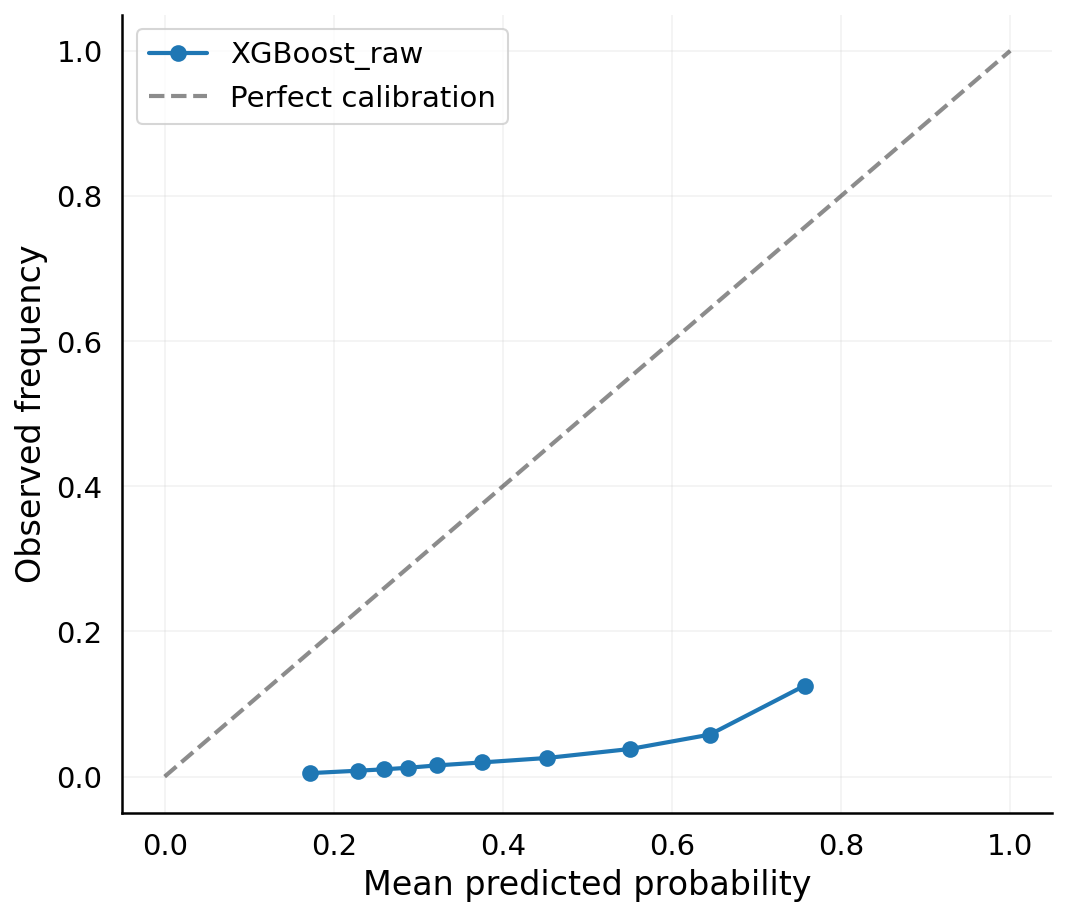

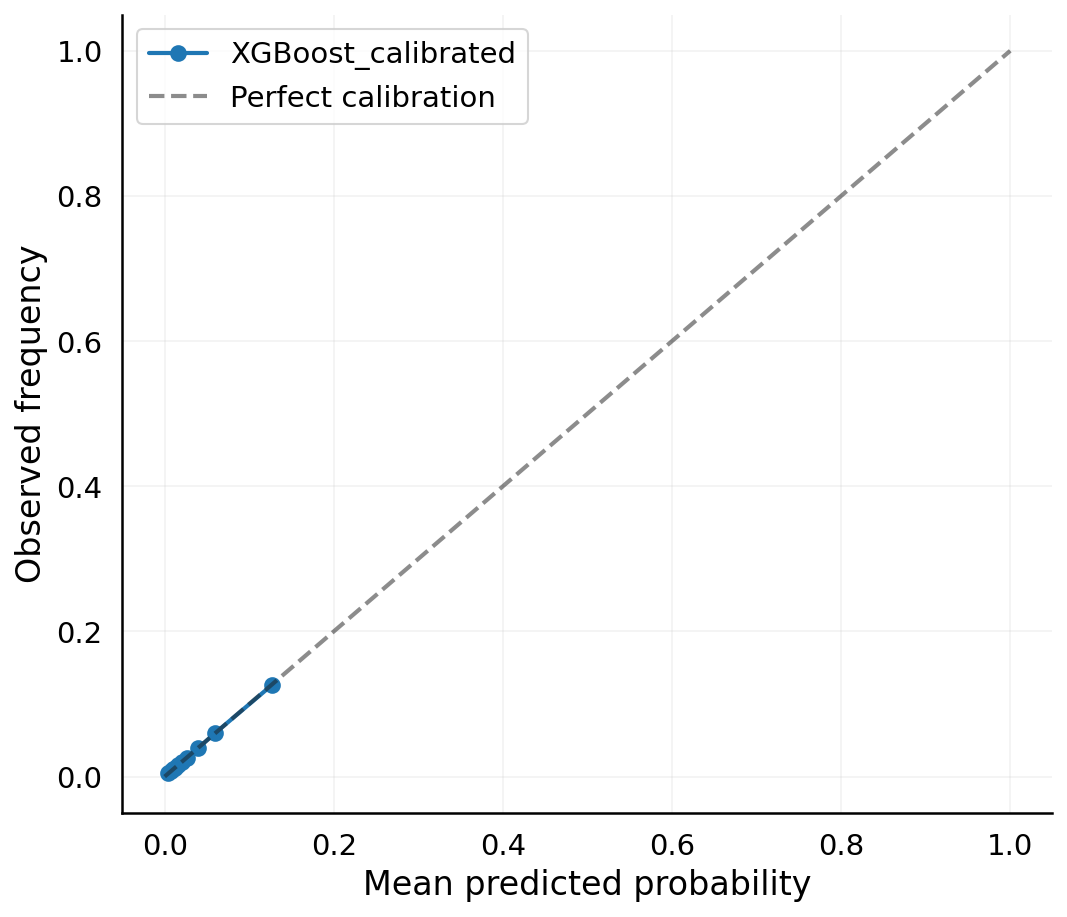

(array([0.00479539, 0.00815622, 0.01016117, 0.01247387, 0.01568623,
        0.02023767, 0.02595298, 0.03894483, 0.06006954, 0.12673621]),
 array([0.00450328, 0.008033  , 0.01009366, 0.01229154, 0.01577171,
        0.02001435, 0.02618668, 0.03923412, 0.05984912, 0.12744283]))

In [39]:
# ── 5.2 Calibration of the selected no-show model ────────────────────────────
# The test set is split into a calibration subset (fit) and a disjoint
# evaluation subset, to avoid calibrating and evaluating on the same data
# (see the docstring of calibrate_and_select).
calibrated_noshow_model, calib_comparison, X_calib_eval, y_calib_eval = calibrate_and_select(
    best_noshow_model, X_test, y_test_ns, methods=CALIB_METHODS,
    calib_fraction=CALIB_FRACTION, random_state=RANDOM_STATE,
)
raw_prob_eval = best_noshow_model.predict_proba(X_calib_eval)[:, 1]
plot_calibration_curve_(y_calib_eval, raw_prob_eval, f"{best_noshow_name}_raw", n_bins=CALIB_BINS, prefix="calib")

calibrated_prob_eval = calibrated_noshow_model.predict_proba(X_calib_eval)[:, 1]
plot_calibration_curve_(y_calib_eval, calibrated_prob_eval, f"{best_noshow_name}_calibrated", n_bins=CALIB_BINS, prefix="calib")


In [40]:
# ── 5.3 Selected group model ──────────────────────────────────────────────────
best_group_name = FORCE_GROUP_MODEL or results_group.set_index("Model")[SELECTION_METRIC].idxmax()
best_group_model = group_models[best_group_name]
print(f"Best group classifier (test {SELECTION_METRIC}): {best_group_name}")
display(results_group.set_index("Model").loc[[best_group_name]])


Best group classifier (test AUC): XGBoost


,AUC,Accuracy,Precision,Recall,F1-score,Threshold
Model,,,,,,
XGBoost,0.73,0.79,0.61,0.62,0.62,0.61


## 6. Deployment

Serialisation of the three inference artifacts (calibrated no-show model, service_time→group tree for interpretability, group classifier for inference on new patients) and of the preprocessing objects fitted on the training set. `predict_patient` is the single inference entry point, used as-is by section 7.

In [41]:
# ── 6.1 Serialise the artifacts ───────────────────────────────────────────────
save_artifacts(
    calibrated_noshow_model, cluster_tree, best_group_model,
    scaler, cat_encodings, feature_cols, name_prefix="final",
)


Artifacts saved to models/ with prefix 'final_'.


In [42]:
# ── 6.2 predict_patient demonstration on a test-set sample ──────────────────
demo_scores = predict_patient(
    X_test.head(10), calibrated_noshow_model, best_group_model,
    positive_group_label="A", reference_group_label="B",
)
demo_scores["NoShow_actual"] = test_df["NoShow"].head(10).values
display(demo_scores)


,q_i,group,NoShow_actual
13850311,0.978993,B,0
25598837,0.905830,B,0
493779,0.963037,B,0
25062792,0.992132,B,0
30344741,0.990773,B,0
21944813,0.938715,B,0
17055336,0.970023,A,0
20155595,0.990023,B,0
311119,0.992132,A,0
13209494,0.975579,A,0


## 7. Solving the ILP (outside CRISP-DM)

The inference holdout (`data/inference/inference_set_raw.csv`, `df_inference`) was never seen by any model of sections 4-6. It is used here to demonstrate the end-to-end bridge: serialised artifacts → `predict_patient` → real ILP instance → `solve_ilp`.

`Instance`/`Config`/`Solution`/`compute_coefficients`/`solve_ilp` are imported from `data_driven_plan.py` — the **same** model core as `01_ilp_validation.ipynb` (regenerated by `notebooks/gen_nb.py`), which carries the full experimental campaign (illustrative example, design of experiments, benchmarks B1-B4, out-of-sample simulation, sensitivity analysis). This section does not duplicate it: it adds the missing step — building an instance from **real patients never used in training**, rather than from synthetic patients drawn from distributions calibrated on aggregate statistics.

In [43]:
# ── 7.1 Load the serialised artifacts ─────────────────────────────────────────
artifacts = load_artifacts(name_prefix="final")
print("Artifacts loaded:", list(artifacts.keys()))


Artifacts loaded: ['noshow_model', 'cluster_tree', 'group_classifier', 'scaler', 'cat_encodings', 'feature_cols']


In [44]:
# ── 7.2 Inference on the holdout patients (never trained on) ────────────────
scored_inference = predict_patient(
    X_inference, artifacts["noshow_model"], artifacts["group_classifier"],
    positive_group_label="A", reference_group_label="B",
)
scored_inference["NoShow_actual"] = df_inference["NoShow"].values
scored_inference["group_label_actual"] = df_sample.loc[df_inference.index, "group_label"].values

print("Predictions on patients never seen during training:")
display(scored_inference.head(10))
print(f"\nMean predicted show-up rate (q_i): {scored_inference['q_i'].mean():.3f}"
      f"   |   observed (1-NoShow): {(1 - scored_inference['NoShow_actual']).mean():.3f}")
print(f"Predicted group distribution:\n{scored_inference['group'].value_counts()}")
print(f"Actual group distribution   :\n{scored_inference['group_label_actual'].value_counts()}")


Predictions on patients never seen during training:


,q_i,group,NoShow_actual,group_label_actual
20015038,0.990952,A,0,B
27918929,0.990023,B,0,B
2955949,0.984994,A,0,B
32996263,0.949809,B,0,B
27994990,0.977236,A,0,B
20896716,0.942753,B,0,B
17759841,0.992132,B,0,B
22500930,0.990773,B,0,B
24787000,0.983538,B,0,B
11700860,0.933103,B,0,B



Mean predicted show-up rate (q_i): 0.968   |   observed (1-NoShow): 0.968
Predicted group distribution:
group
B    2321864
A    1691477
Name: count, dtype: int64
Actual group distribution   :
group_label_actual
B    3391879
A     621462
Name: count, dtype: int64


In [45]:
# ── 7.3 Build a real ILP instance (one clinic day) ──────────────────────────
N_DEMO = 30  # size of an illustrative day, at realistic scale
demo_patients = scored_inference.sample(n=min(N_DEMO, len(scored_inference)), random_state=RANDOM_STATE)

T_demo = [6]
L_demo = [[30.0, 30.0, 30.0, 60.0, 60.0, 60.0]]
s_A_real = service_time_by_group["A"]
s_B_real = service_time_by_group["B"]

real_instance = build_instance_from_patients(
    demo_patients, T=T_demo, L=L_demo, s_A=s_A_real, s_B=s_B_real,
    c_I=1.0, c_W=0.5, c_O=0.5, group_col="group", q_col="q_i", positive_group="A",
)
print(f"Real instance: n={real_instance.n} patients, {sum(T_demo)} slots "
      f"(max capacity {2*sum(T_demo)} seats), s_A={s_A_real:.1f} min, s_B={s_B_real:.1f} min")


Real instance: n=30 patients, 6 slots (max capacity 12 seats), s_A=64.2 min, s_B=13.0 min


In [46]:
# ── 7.4 Solve ─────────────────────────────────────────────────────────────────
real_solution = solve_ilp(real_instance, Config(time_limit=60.0))
print(f"Solve time: {real_solution.solve_time:.3f} s   |   MIP gap: {real_solution.gap:.2e}")
print(f"Z_reduced = {real_solution.Z_reduced:.4f}   Z_complete = {real_solution.Z_complete:.4f}")
print(f"E[Idle]={real_solution.E_idle:.3f}  E[Wait]={real_solution.E_wait:.3f}  E[OT]={real_solution.E_OT:.3f}")
print(f"Patients served: {real_solution.n_served}/{real_instance.n}   "
      f"Double-booked slots: {real_solution.n_double}/{sum(T_demo)}")


Solve time: 2.898 s   |   MIP gap: 0.00e+00
Z_reduced = -230.0712   Z_complete = 39.9288
E[Idle]=14.489  E[Wait]=19.133  E[OT]=6.307
Patients served: 9/30   Double-booked slots: 3/6


**Full experimental campaign** (design of experiments with distributional notation and factor levels, benchmarks B1-B4, out-of-sample simulation, sensitivity analysis to the no-show rate / variance / load with percentage deviation and solve time): see the companion notebook **`01_ilp_validation.ipynb`**, regenerated by `notebooks/gen_nb.py` and not included in this repository. It imports its model core (`Instance`/`Config`/`solve_ilp`) from `data_driven_plan.py`, so both solve exactly the same model.

## Final summary

In [47]:
# ── Summary table ─────────────────────────────────────────────────────────────
recap = pd.DataFrame([
    {"Item": "Split", "Value": f"{len(df_sample):,} rows (full dataset) | "
     f"train={len(train_df):,} test={len(test_df):,} inference={len(df_inference):,}"},
    {"Item": "No-show — best model", "Value": best_noshow_name},
    {"Item": "No-show — AUC (test)",
     "Value": f"{results_noshow.set_index('Model').loc[best_noshow_name, 'AUC']:.4f}"},
    {"Item": "No-show — Brier (calibrated)",
     "Value": f"{calib_comparison.set_index('Method').loc[calib_comparison.iloc[0]['Method'], 'Brier']:.4f}"},
    {"Item": "service_time clustering — selected K", "Value": str(best_k)},
    {"Item": "Clustering — bootstrapped silhouette", "Value": f"mean={mu_sil:.4f}, sd={sd_sil:.4f}"},
    {"Item": "Cutoff (decision tree)", "Value": f"{primary_cutoff:.1f} min"},
    {"Item": "Group — best classifier", "Value": best_group_name},
    {"Item": "Group — AUC (test)",
     "Value": f"{results_group.set_index('Model').loc[best_group_name, 'AUC']:.4f}"},
    {"Item": "ILP — real instance (n patients)", "Value": str(real_instance.n)},
    {"Item": "ILP — Z_complete", "Value": f"{real_solution.Z_complete:.4f}"},
    {"Item": "ILP — solve time", "Value": f"{real_solution.solve_time:.3f} s"},
])
display(recap)
save_dataframe(recap, "results/recap_data_driven_plan.csv")
print("Summary saved -> results/recap_data_driven_plan.csv")


,Item,Value
0,Split,"40,133,413 rows (full dataset) | train=28,093,..."
1,No-show — best model,XGBoost
2,No-show — AUC (test),0.7700
3,No-show — Brier (calibrated),0.0288
4,service_time clustering — selected K,2
5,Clustering — bootstrapped silhouette,"mean=0.6917, sd=0.0035"
6,Cutoff (decision tree),38.5 min
7,Group — best classifier,XGBoost
8,Group — AUC (test),0.7300
9,ILP — real instance (n patients),30


Summary saved -> results/recap_data_driven_plan.csv
